# Exploratory data analysis: VisDrone2019-VID

Data understanding for the drone video detection task: frame sizes, classes, object sizes, density, ignored regions, temporal structure, split coverage, and test set.

| # | Section |
| --- | --- |
| 1 | [Setup](#1-setup) |
| 2 | [Data overview](#2-data-overview) |
| 3 | [Frame sizes](#3-frame-sizes) |
| 4 | [Classes](#4-classes) |
| 5 | [Object sizes](#5-object-sizes) |
| 6 | [Density](#6-density) |
| 7 | [Ignored regions](#7-ignored-regions) |
| 8 | [Occlusion and truncation](#8-occlusion-and-truncation) |
| 9 | [Temporal structure](#9-temporal-structure) |
| 10 | [Sample frames](#10-sample-frames) |
| 11 | [Validation coverage](#11-validation-coverage) |
| 12 | [Test set](#12-test-set) |
| 13 | [Anchor shapes](#13-anchor-shapes) |
| 14 | [Summary](#14-summary) |

## 1. Setup

Imports, data root from `DATA_ROOT` (read with `decouple`), seed, and the shared plot theme from `src/visualization/`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns
from decouple import AutoConfig
from IPython.display import Image, display

# make the repository root importable when the kernel starts in notebooks/
PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))
# decouple locates .env from the caller file, which is a temp file inside a kernel
config = AutoConfig(search_path=PROJECT_ROOT)

from src.data.annotations import load_annotations, load_split_clips, load_test_images
from src.data.boxes import (
    add_ignored_coverage_column,
    add_max_iou_columns,
    explode_size_buckets,
    is_in_size_bucket,
)
from src.data.classes import CLASS_NAMES
from src.data.images import (
    compute_color_statistics,
    compute_frame_differences,
    sample_frame_pairs,
)
from src.data.statistics import (
    build_class_table,
    compute_clip_class_shares,
    compute_required_max_size,
    compute_resized_frame_size,
    compute_resize_scale,
    count_class_presence,
    count_objects_per_frame,
    summarize_quantiles,
)
from src.data.tracks import pair_track_boxes, summarize_tracks
from src.models.anchors import (
    cluster_box_shapes,
    compute_best_anchor_iou,
    load_default_anchors,
)
from src.visualization.frames import (
    find_densest_crop,
    plot_frame_with_crop,
    render_figure_as_jpeg,
)
from src.visualization.plots import plot_class_histograms
from src.visualization.style import (
    CLASS_COLORS,
    OCCLUSION_COLORS,
    SPLIT_COLORS,
    TEST_COLOR,
    set_plot_theme,
)

SEED = 42
rng = np.random.default_rng(SEED)
set_plot_theme()

DATA_ROOT = Path(config("DATA_ROOT"))
SPLITS = ("train", "val", "test")
SPLIT_CLIPS = load_split_clips(PROJECT_ROOT / "config" / "data.toml")

In [2]:
# the path itself is not shown: it comes from .env
data_root_check = pl.DataFrame(
    {
        "path": ["DATA_ROOT", *(f"DATA_ROOT/{split}" for split in SPLITS)],
        "is_dir": [DATA_ROOT.is_dir(), *((DATA_ROOT / split).is_dir() for split in SPLITS)],
    }
)
data_root_check

path,is_dir
str,bool
"""DATA_ROOT""",true
"""DATA_ROOT/train""",true
"""DATA_ROOT/val""",true
"""DATA_ROOT/test""",true


`DATA_ROOT` resolves to a directory; `train/`, `val/`, and `test/` all exist.

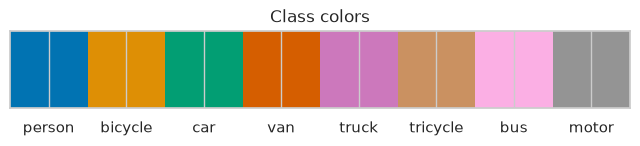

In [3]:
sns.palplot(list(CLASS_COLORS.values()))
plt.xticks(range(len(CLASS_NAMES)), CLASS_NAMES)
plt.title("Class colors")
plt.show()

8 classes, 8 distinct colors, in class id order 0 to 7.

## 2. Data overview

Annotations of both provided files (`train/` and `val/` `annotations_coco.json`), loaded with `src.data.annotations` and assigned to splits by `config/data.toml` `[splits]`. Objects are `iscrowd=0` annotations; ignored regions are `iscrowd=1` annotations, one row per unique region.

The splits are the provided ones with one clip swap made before any training: `uav0000268_05773_v` moved from `val` to `train` and `uav0000263_03289_v` from `train` to `val`; the evidence is in section 11.4. All `train` and `val` numbers in this notebook use the adopted split.

In [4]:
annotations = load_annotations(DATA_ROOT, SPLIT_CLIPS)
images, objects, ignored = annotations

In [5]:
frames_per_clip = (
    images.group_by("split", "clip")
    .len("frames")
    .group_by("split")
    .agg(
        pl.col("clip").n_unique().alias("clips"),
        pl.col("frames").sum(),
        pl.col("frames").min().alias("frames_per_clip_min"),
        pl.col("frames").median().alias("frames_per_clip_median"),
        pl.col("frames").max().alias("frames_per_clip_max"),
    )
)
split_overview = (
    frames_per_clip.join(objects.group_by("split").len("objects"), on="split")
    .join(ignored.group_by("split").len("ignored_regions"), on="split")
    .select(
        "split", "clips", "frames", "objects", "ignored_regions",
        pl.selectors.starts_with("frames_per_clip"),
    )
    .sort(pl.col("split") == "val")
)
split_overview

split,clips,frames,objects,ignored_regions,frames_per_clip_min,frames_per_clip_median,frames_per_clip_max
str,u32,u32,u32,u32,u32,f64,u32
"""train""",56,24454,1114408,62929,58,383.5,1424
"""val""",7,2593,105240,4909,184,349.0,725


- `train`: 56 clips, 24,454 frames, 1,114,408 objects, 62,929 ignored regions; frames per clip min 58, median 383.5, max 1,424.
- `val`: 7 clips, 2,593 frames, 105,240 objects, 4,909 ignored regions; frames per clip min 184, median 349, max 725.
- The provided split has 24,201 `train` and 2,846 `val` frames; the difference is the swap (section 11.4).

Check on the raw provided files: copies of each ignored region (`iscrowd=1`, same frame, box, and `orig_category_id`) and the distinct `category_id` values among them. `split` here is the provided file, not the adopted split.

In [6]:
def count_ignored_region_copies(split: str) -> pl.DataFrame:
    coco = json.loads((DATA_ROOT / split / "annotations_coco.json").read_text())
    crowd = pl.DataFrame(
        [a for a in coco["annotations"] if a["iscrowd"] == 1], infer_schema_length=None
    )
    regions = crowd.group_by("image_id", "bbox", "orig_category_id").agg(
        pl.len().alias("copies"), pl.col("category_id").n_unique().alias("category_ids")
    )
    return regions.select(
        pl.lit(split).alias("split"),
        pl.lit(crowd.height).alias("crowd_annotations"),
        pl.len().alias("unique_regions"),
        pl.col("copies").min().alias("copies_min"),
        pl.col("copies").max().alias("copies_max"),
        pl.col("category_ids").min().alias("category_ids_min"),
        pl.col("category_ids").max().alias("category_ids_max"),
    )


pl.concat([count_ignored_region_copies(split) for split in ("train", "val")])

split,crowd_annotations,unique_regions,copies_min,copies_max,category_ids_min,category_ids_max
str,i32,u32,u32,u32,u32,u32
"""train""",510744,63843,8,8,8,8
"""val""",31960,3995,8,8,8,8


- Every ignored region appears exactly 8 times, once per `category_id` 1 to 8: 510,744 `iscrowd=1` annotations form 63,843 regions in the `train` file, 31,960 form 3,995 in the `val` file.
- The unique regions of both files sum to 67,838, the total of the `ignored_regions` column of the overview table.

## 3. Frame sizes

Distinct frame sizes (width × height, px) of `train` and `val` from `annotations_coco.json` and of `test` from `test_images.csv`.

In [7]:
test_images = load_test_images(DATA_ROOT)
all_images = pl.concat(
    [images.select(test_images.columns).drop("image_id"), test_images.drop("image_id")]
).with_columns(pl.col("split").cast(pl.Enum(["train", "val", "test"])))

frame_sizes = (
    all_images.group_by("split", "width", "height")
    .agg(pl.col("clip").n_unique().alias("clips"), pl.len().alias("frames"))
    .with_columns(
        (pl.col("frames") / pl.col("frames").sum().over("split"))
        .round(3)
        .alias("frame_share"),
        ((pl.col("width") == 1920) & (pl.col("height") == 1080)).alias("is_1920x1080"),
    )
    .sort("split", "width", "height", descending=[False, True, True])
)
with pl.Config(tbl_rows=-1):
    display(frame_sizes)

split,width,height,clips,frames,frame_share,is_1920x1080
enum,i64,i64,u32,u32,f64,bool
"""train""",3840,2160,1,978,0.04,false
"""train""",2720,1530,2,473,0.019,false
"""train""",2688,1512,11,3505,0.143,false
"""train""",1920,1080,1,721,0.029,true
"""train""",1904,1071,29,12170,0.498,false
"""train""",1360,765,1,962,0.039,false
"""train""",1344,756,11,5645,0.231,false
"""val""",2720,1530,1,349,0.135,false
"""val""",2688,1512,1,233,0.09,false


- `train`: 7 sizes from 1344 × 756 to 3840 × 2160 px. 1904 × 1071 covers 29 clips and 49.8% of frames; 1920 × 1080 occurs in 1 clip (721 frames, 2.9%); 3840 × 2160 in 1 clip (978 frames, 4.0%).
- `val`: 4 sizes from 1344 × 756 to 2720 × 1530 px. 1904 × 1071 covers 3 clips and 45.7% of frames; no frame is 1920 × 1080.
- `test`: 6 sizes from 680 × 382 to 1920 × 1080 px. 1360 × 764 covers 18 clips and 38.7% of frames; 1920 × 1080 covers 11 clips and 26.0%.
- The largest `val` size is 2720 × 1530 px; 3840 × 2160 occurs only in `train`.

In [8]:
# frames that differ from 1920 x 1080, and clips with more than one frame size
all_images.group_by("split").agg(
    ((pl.col("width") != 1920) | (pl.col("height") != 1080))
    .sum()
    .alias("frames_not_1920x1080"),
    pl.len().alias("frames"),
    (pl.struct("width", "height").n_unique().over("clip") > 1)
    .filter(pl.col("clip").is_first_distinct())
    .sum()
    .alias("clips_with_several_sizes"),
).sort("split")

split,frames_not_1920x1080,frames,clips_with_several_sizes
enum,u32,u32,u32
"""train""",23733,24454,0
"""val""",2593,2593,0
"""test""",2820,3811,0


- Frames different from 1920 × 1080: 23,733 of 24,454 in `train`, 2,593 of 2,593 in `val`, 2,820 of 3,811 in `test`.
- No clip contains more than one frame size.

In [9]:
clips_by_size = (
    all_images.group_by("split", "width", "height")
    .agg(pl.col("clip").unique().sort().str.join(", ").alias("clips"))
    .sort("split", "width", "height", descending=[False, True, True])
)
with pl.Config(tbl_rows=-1, fmt_str_lengths=2000, tbl_width_chars=2000):
    display(clips_by_size)

split,width,height,clips
enum,i64,i64,str
"""train""",3840,2160,"""uav0000268_05773_v"""
"""train""",2720,1530,"""uav0000295_02300_v, uav0000316_01288_v"""
"""train""",2688,1512,"""uav0000124_00944_v, uav0000126_00001_v, uav0000138_00000_v, uav0000140_01590_v, uav0000143_02250_v, uav0000145_00000_v, uav0000150_02310_v, uav0000218_00001_v, uav0000222_03150_v, uav0000266_03598_v, uav0000266_04830_v"""
"""train""",1920,1080,"""uav0000244_01440_v"""
"""train""",1904,1071,"""uav0000071_03240_v, uav0000072_04488_v, uav0000072_05448_v, uav0000072_06432_v, uav0000076_00720_v, uav0000079_00480_v, uav0000264_02760_v, uav0000270_00001_v, uav0000273_00001_v, uav0000279_00001_v, uav0000281_00460_v, uav0000288_00001_v, uav0000289_00001_v, uav0000289_06922_v, uav0000300_00000_v, uav0000307_00000_v, uav0000308_00000_v, uav0000308_01380_v, uav0000309_00000_v, uav0000315_00000_v, uav0000323_01173_v, uav0000326_01035_v, uav0000329_04715_v, uav0000342_04692_v, uav0000352_05980_v, uav0000357_00920_v, uav0000360_00001_v, uav0000361_02323_v, uav0000366_00001_v"""
"""train""",1360,765,"""uav0000278_00001_v"""
"""train""",1344,756,"""uav0000013_00000_v, uav0000013_01073_v, uav0000013_01392_v, uav0000020_00406_v, uav0000084_00000_v, uav0000099_02109_v, uav0000239_03720_v, uav0000239_12336_v, uav0000243_00001_v, uav0000248_00001_v, uav0000363_00001_v"""
"""val""",2720,1530,"""uav0000117_02622_v"""
"""val""",2688,1512,"""uav0000137_00458_v"""


- The only 3840 × 2160 clip, `uav0000268_05773_v`, is in `train`.
- `test` sizes absent from `train` and `val`: 960 × 540 (5 clips, 279 frames) and 680 × 382 (3 clips, 321 frames), plus 1904 × 1072 and 1360 × 764, which differ by 1 px in height from `train` sizes 1904 × 1071 and 1360 × 765.

## 4. Classes

Labelled objects (`iscrowd=0`) per class in `train` and `val`: instances, frames and clips that contain each class, and the class mix of every clip.

In [10]:
class_presence = count_class_presence(images, objects)
class_counts = class_presence.pivot(
    on="split",
    index=["class_id", "class_name"],
    values=["instances", "instance_share", "frames", "frame_share"],
).with_columns(pl.selectors.ends_with("share_train", "share_val").round(3))
class_counts

class_id,class_name,instances_train,instances_val,instance_share_train,instance_share_val,frames_train,frames_val,frame_share_train,frame_share_val
i64,str,u32,u32,f64,f64,u32,u32,f64,f64
0,"""person""",330685,48328,0.297,0.459,22934,1810,0.938,0.698
1,"""bicycle""",40114,6163,0.036,0.059,12573,1123,0.514,0.433
2,"""car""",512470,24652,0.46,0.234,21373,2031,0.874,0.783
3,"""van""",48623,5159,0.044,0.049,15816,1559,0.647,0.601
4,"""truck""",29168,2689,0.026,0.026,11342,1138,0.464,0.439
5,"""tricycle""",41859,4977,0.038,0.047,13541,1152,0.554,0.444
6,"""bus""",8896,1021,0.008,0.01,5987,821,0.245,0.317
7,"""motor""",102593,12251,0.092,0.116,16842,2094,0.689,0.808


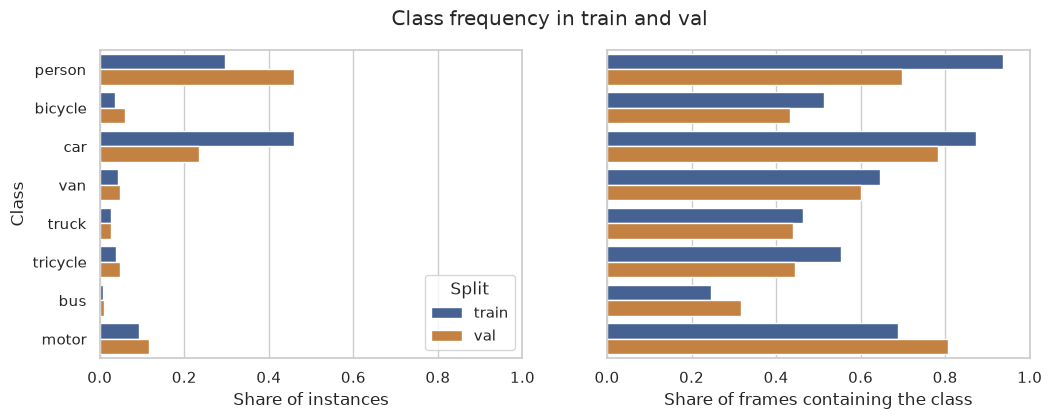

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (column, label) in zip(
    axes,
    [
        ("instance_share", "Share of instances"),
        ("frame_share", "Share of frames containing the class"),
    ],
):
    sns.barplot(
        class_presence.to_dict(as_series=False),
        y="class_name",
        x=column,
        hue="split",
        palette=SPLIT_COLORS,
        ax=ax,
    )
    ax.set(xlabel=label, ylabel="", xlim=(0, 1))
axes[0].set_ylabel("Class")
axes[1].get_legend().remove()
axes[0].legend(title="Split", loc="lower right")
fig.suptitle("Class frequency in train and val")
plt.show()

- `train` instance shares: car 46.0%, person 29.7%, motor 9.2%, van 4.4%, tricycle 3.8%, bicycle 3.6%, truck 2.6%, bus 0.80% (8,896 instances).
- `val` instance shares: person 45.9%, car 23.4%, motor 11.6%, bicycle 5.9%, van 4.9%, tricycle 4.7%, truck 2.6%, bus 0.97% (1,021 instances).
- Ratio of most to least frequent class: car / bus 58 in `train`, person / bus 47 in `val`.
- Share of frames containing the class, `train` / `val`: person 93.8% / 69.8%, car 87.4% / 78.3%, motor 68.9% / 80.8%, van 64.7% / 60.1%, bicycle 51.4% / 43.3%, truck 46.4% / 43.9%, bus 24.5% / 31.7%.

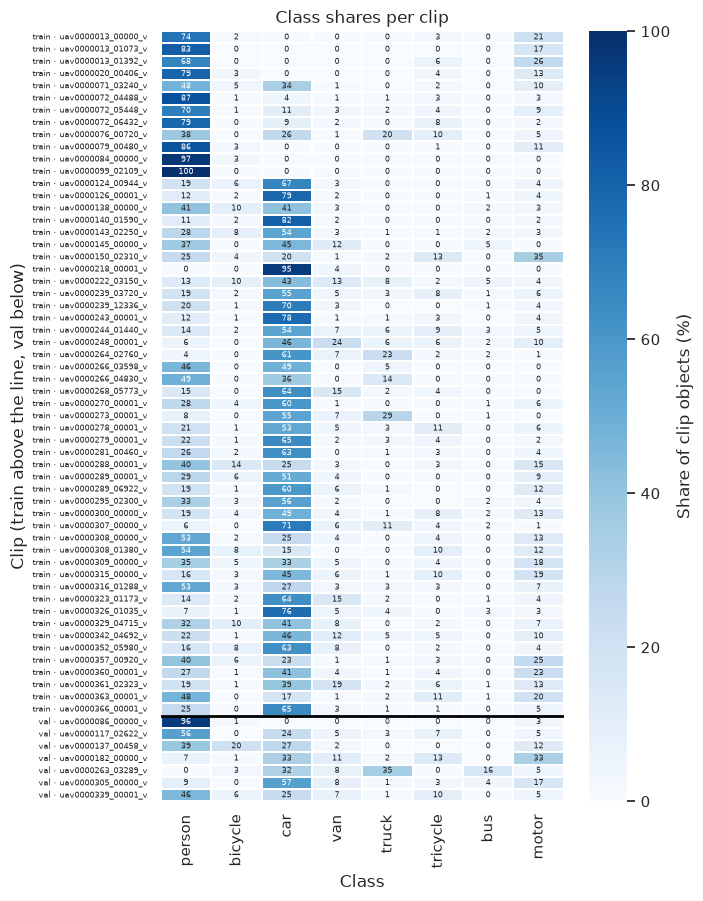

In [12]:
clip_class_shares = compute_clip_class_shares(images, objects)
clip_labels = clip_class_shares.select(pl.concat_str("split", "clip", separator=" · "))
fig, ax = plt.subplots(figsize=(6.5, 10))
sns.heatmap(
    clip_class_shares.select(CLASS_NAMES).to_numpy() * 100,
    xticklabels=CLASS_NAMES,
    yticklabels=clip_labels.to_series().to_list(),
    cmap="Blues",
    vmin=0,
    vmax=100,
    annot=True,
    fmt=".0f",
    annot_kws={"fontsize": 5.5},
    linewidths=0.3,
    cbar_kws={"label": "Share of clip objects (%)"},
    ax=ax,
)
train_clips = clip_class_shares.filter(pl.col("split") == "train").height
ax.axhline(train_clips, color="black", linewidth=2)
ax.set(
    xlabel="Class",
    ylabel="Clip (train above the line, val below)",
    title="Class shares per clip",
)
ax.tick_params(axis="y", labelsize=5.5)
plt.show()

- Clips where one class is at least 80% of objects: 7 of 56 in `train` (5 person, 2 car), 1 of 7 in `val` (`uav0000086_00000_v`, person 95.7%).
- `val` bus instances are in `uav0000263_03289_v` (16.2% of its objects) and `uav0000305_00000_v` (4.1%); the largest bus share of a `train` clip is 5.5% (`uav0000222_03150_v`).

In [13]:
class_presence.pivot(
    on="split", index="class_name", values=["clips", "clip_share"]
).with_columns(pl.selectors.starts_with("clip_share").round(3))

class_name,clips_train,clips_val,clip_share_train,clip_share_val
str,u32,u32,f64,f64
"""person""",56,6,1.0,0.857
"""bicycle""",40,6,0.714,0.857
"""car""",49,6,0.875,0.857
"""van""",46,6,0.821,0.857
"""truck""",39,5,0.696,0.714
"""tricycle""",40,4,0.714,0.571
"""bus""",23,2,0.411,0.286
"""motor""",49,7,0.875,1.0


- `train`: person in 56 of 56 clips, bus in 23, all other classes in 39 to 49.
- `val`: motor in 7 of 7 clips, person in 6, bus in 2, all other classes in 4 to 6.
- Every class occurs in at least two `val` clips.

## 5. Object sizes

Box width, height, and $\sqrt{\text{area}}$ in original pixels, COCO size buckets as in the evaluator (small [0, 32²], medium [32², 96²], large [96², ∞) px², ends inclusive, so a box of exactly 32² or 96² px² counts in both adjacent buckets), aspect ratio $h / w$, and box sizes after the torchvision detection resize with `min_size` 1024.

In [14]:
QUANTILES = (0.05, 0.25, 0.5, 0.75, 0.95)
QUANTILE_NAMES = tuple(f"p{round(q * 100)}" for q in QUANTILES)
CLASS_ORDER = pl.Enum(["all", *CLASS_NAMES])
# log-spaced bin edges snapped to half pixels, so integer box sizes do not create comb artifacts
SIZE_BINS = np.unique(np.round(np.geomspace(4, 1024, 49))) - 0.5
object_shapes = (
    objects.join(images.select("split", "image_id", "width", "height"), on=["split", "image_id"])
    .join(build_class_table(), on="class_id")
    .with_columns(
        pl.col("class_name").cast(CLASS_ORDER),
        pl.col("area").sqrt().alias("sqrt_area"),
        (pl.col("h") / pl.col("w")).alias("aspect_ratio"),
    )
)
# the same objects once more under class "all", for overall rows in per-class tables
object_shapes_with_all = pl.concat(
    [object_shapes.with_columns(pl.lit("all").cast(CLASS_ORDER).alias("class_name")), object_shapes]
)

### 5.1 Width, height, and square root of area

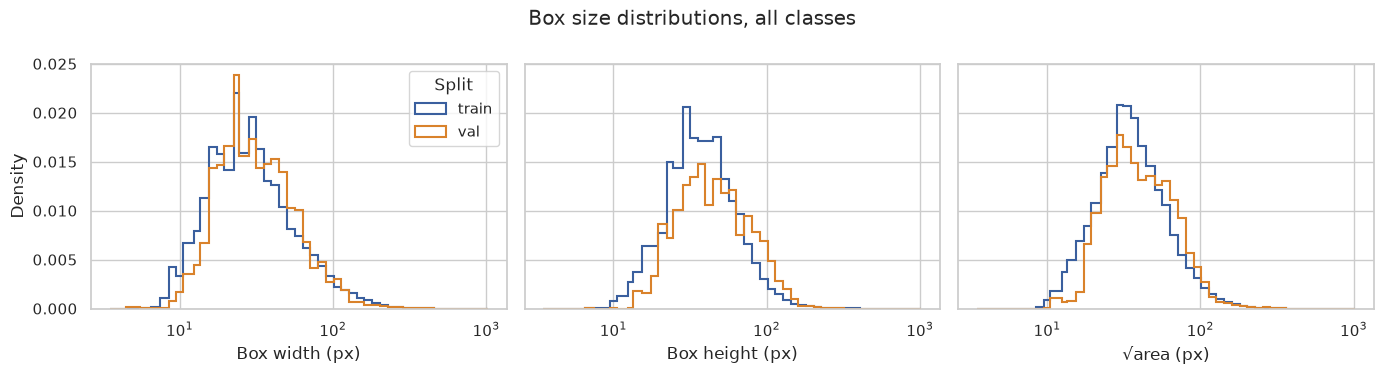

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
size_columns = [("w", "Box width (px)"), ("h", "Box height (px)"), ("sqrt_area", "√area (px)")]
for ax, (column, label) in zip(axes, size_columns):
    for split, color in SPLIT_COLORS.items():
        values = object_shapes.filter(pl.col("split") == split)[column].to_numpy()
        ax.hist(
            values, bins=SIZE_BINS, density=True, histtype="step", linewidth=1.5, color=color,
            label=split,
        )
    ax.set(xscale="log", xlabel=label)
axes[0].set_ylabel("Density")
axes[0].legend(title="Split")
fig.suptitle("Box size distributions, all classes")
fig.tight_layout()
plt.show()

In [16]:
box_sizes = (
    summarize_quantiles(object_shapes_with_all, "sqrt_area", ["split", "class_name"], QUANTILES)
    .rename(lambda name: f"sqrt_area_{name}" if name in ("mean", *QUANTILE_NAMES) else name)
    .join(
        object_shapes_with_all.group_by("split", "class_name").agg(
            pl.col("w").median().alias("w_p50"), pl.col("h").median().alias("h_p50")
        ),
        on=["split", "class_name"],
    )
    .sort("split", "class_name")
    .with_columns(pl.selectors.float().round(1))
)
with pl.Config(tbl_rows=-1, tbl_cols=-1):
    display(box_sizes)

split,class_name,count,sqrt_area_mean,sqrt_area_p5,sqrt_area_p25,sqrt_area_p50,sqrt_area_p75,sqrt_area_p95,w_p50,h_p50
str,enum,u32,f64,f64,f64,f64,f64,f64,f64,f64
"""train""","""all""",1114408,56.7,19.8,32.0,45.7,67.7,130.6,44.0,48.0
"""train""","""person""",330685,38.3,16.6,26.8,35.7,47.7,67.7,25.0,50.0
"""train""","""bicycle""",40114,44.6,20.0,32.4,41.4,52.8,82.3,43.0,43.0
"""train""","""car""",512470,67.7,23.4,37.9,56.9,85.7,148.5,67.0,47.0
"""train""","""van""",48623,66.4,24.1,33.4,50.9,80.0,168.6,57.0,47.0
"""train""","""truck""",29168,90.1,28.5,45.3,74.2,112.5,213.9,82.0,69.0
"""train""","""tricycle""",41859,61.6,21.4,35.9,54.8,77.7,133.0,58.0,51.0
"""train""","""bus""",8896,127.4,32.4,58.7,106.6,169.7,291.4,109.0,101.0
"""train""","""motor""",102593,43.0,16.5,29.5,40.2,53.4,77.9,38.0,43.0


- Median √area: 45.7 px in `train`, 53.4 px in `val`; 5th to 95th percentile 19.8 to 130.6 px in `train`, 22.4 to 124.9 px in `val`.
- Median width × height: 44 × 48 px in `train`, 45 × 60 px in `val`.
- Median √area per class in `train`: person 35.7, motor 40.2, bicycle 41.4, van 50.9, tricycle 54.8, car 56.9, truck 74.2, bus 106.6 px.
- Median √area per class in `val`: motor 35.3, person 48.5, tricycle 53.0, van 56.0, bicycle 66.7, car 70.3, truck 72.6, bus 161.0 px.

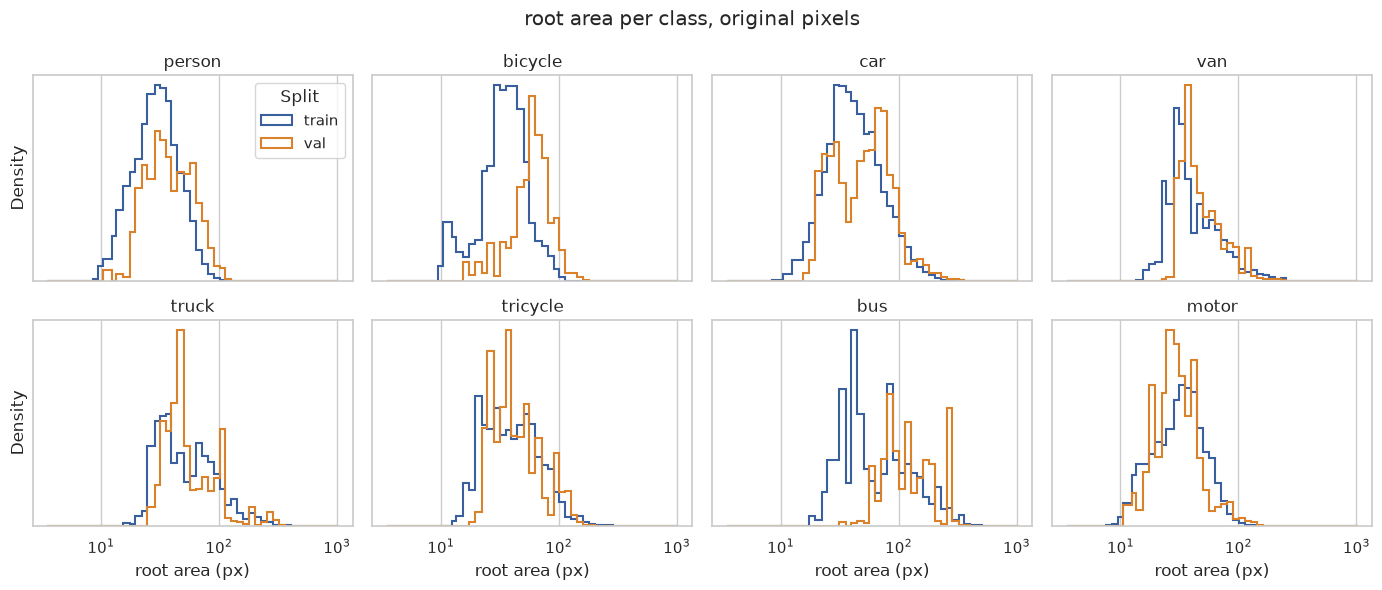

In [17]:
fig = plot_class_histograms(
    object_shapes, "sqrt_area", SIZE_BINS, "root area (px)", "root area per class, original pixels"
)
plt.show()

- Largest `val` / `train` ratio of median √area: bicycle 1.61 (66.7 / 41.4 px), bus 1.51 (161.0 / 106.6 px), person 1.36 (48.5 / 35.7 px).
- `val` bus 5th percentile √area is 70.7 px, `train` bus 32.4 px.

### 5.2 COCO size buckets

In [18]:
# shares of all objects; boxes on a bucket boundary count in both buckets, as in COCO
size_bucket_shares = (
    explode_size_buckets(object_shapes_with_all, pl.col("area"))
    .group_by("split", "class_name", "size_bucket")
    .len()
    .join(
        object_shapes_with_all.group_by("split", "class_name").len("objects"),
        on=["split", "class_name"],
    )
    .with_columns((pl.col("len") / pl.col("objects")).round(3))
    .pivot(on="size_bucket", index=["split", "class_name"], values="len")
    .select("split", "class_name", "small", "medium", "large")
    .fill_null(0)
    .sort("split", "class_name")
)
with pl.Config(tbl_rows=-1):
    display(size_bucket_shares)

split,class_name,small,medium,large
str,enum,f64,f64,f64
"""train""","""all""",0.249,0.636,0.116
"""train""","""person""",0.397,0.599,0.003
"""train""","""bicycle""",0.243,0.742,0.015
"""train""","""car""",0.161,0.649,0.19
"""train""","""van""",0.209,0.622,0.17
"""train""","""truck""",0.097,0.572,0.331
"""train""","""tricycle""",0.213,0.661,0.127
"""train""","""bus""",0.045,0.414,0.542
"""train""","""motor""",0.303,0.683,0.014


- All classes, small / medium / large: 24.9% / 63.6% / 11.6% in `train`, 19.6% / 68.8% / 11.7% in `val`.
- Highest small shares: person 39.7% and motor 30.3% in `train`; motor 41.0% and person 22.4% in `val`.
- Lowest small shares: bus 4.5% in `train`; bus 0.0%, truck 2.9%, bicycle 4.0% in `val` (bicycle 24.3% in `train`).

### 5.3 Aspect ratio

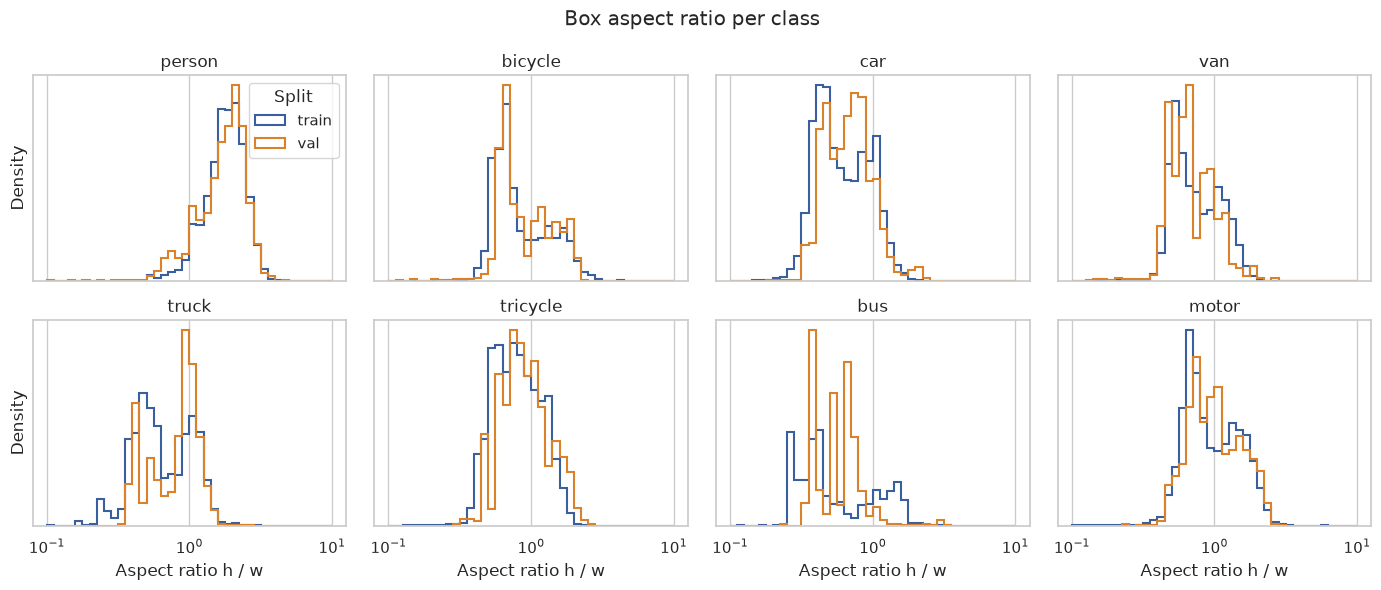

In [19]:
fig = plot_class_histograms(
    object_shapes, "aspect_ratio", np.geomspace(0.1, 10, 41), "Aspect ratio h / w",
    "Box aspect ratio per class",
)
plt.show()

In [20]:
aspect_ratios = (
    summarize_quantiles(object_shapes_with_all, "aspect_ratio", ["split", "class_name"], QUANTILES)
    .drop("count", "mean")
    .with_columns(pl.selectors.float().round(2))
)
with pl.Config(tbl_rows=-1):
    display(aspect_ratios)

split,class_name,p5,p25,p50,p75,p95
str,enum,f64,f64,f64,f64,f64
"""train""","""all""",0.41,0.68,1.05,1.69,2.54
"""train""","""person""",1.13,1.65,2.0,2.37,2.94
"""train""","""bicycle""",0.52,0.68,1.06,1.65,2.23
"""train""","""car""",0.37,0.51,0.79,1.02,1.36
"""train""","""van""",0.49,0.6,0.9,1.19,1.55
"""train""","""truck""",0.39,0.55,0.92,1.15,1.43
"""train""","""tricycle""",0.49,0.69,0.94,1.26,1.64
"""train""","""bus""",0.28,0.43,1.02,1.43,1.74
"""train""","""motor""",0.59,0.78,1.24,1.67,2.17


- Median h / w in `train`: person 2.00, motor 1.24, bicycle 1.06, bus 1.02, tricycle 0.94, truck 0.92, van 0.90, car 0.79.
- 5th to 95th percentile over all classes: 0.41 to 2.54 in `train`, 0.50 to 2.68 in `val`.
- `val` bus median h / w is 0.69, `train` bus 1.02.

### 5.4 Frame aspect ratio and resize

torchvision scales a frame by $\min(\text{min\_size} / \text{short side},\ \text{max\_size} / \text{long side})$. `required_max_size` is the smallest `max_size` for which the shorter side reaches `min_size` 1024.

In [21]:
MIN_SIZE = 1024
frame_resize = (
    all_images.group_by("split", "width", "height")
    .agg(pl.len().alias("frames"))
    .with_columns(
        (pl.col("width") / pl.col("height")).round(4).alias("aspect_ratio"),
        compute_required_max_size(MIN_SIZE).alias("required_max_size"),
    )
    .sort("split", "width", descending=[False, True])
)
MAX_SIZE: int = frame_resize.select(pl.col("required_max_size").max()).item()
frame_resize = frame_resize.with_columns(
    compute_resize_scale(MIN_SIZE, MAX_SIZE).round(4).alias("scale"),
    *compute_resized_frame_size(MIN_SIZE, MAX_SIZE),
)
with pl.Config(tbl_rows=-1, tbl_cols=-1):
    display(frame_resize)
display(
    frame_resize.group_by("split")
    .agg(pl.col("required_max_size").max())
    .sort("split")
    .with_columns(pl.lit(MAX_SIZE).alias("max_size_all_splits"))
)

split,width,height,frames,aspect_ratio,required_max_size,scale,resized_width,resized_height
enum,i64,i64,u32,f64,i64,f64,i64,i64
"""train""",3840,2160,978,1.7778,1821,0.4741,1820,1024
"""train""",2720,1530,473,1.7778,1821,0.6693,1820,1023
"""train""",2688,1512,3505,1.7778,1821,0.6772,1820,1024
"""train""",1920,1080,721,1.7778,1821,0.9481,1820,1024
"""train""",1904,1071,12170,1.7778,1821,0.9561,1820,1024
"""train""",1360,765,962,1.7778,1821,1.3386,1820,1023
"""train""",1344,756,5645,1.7778,1821,1.3545,1820,1024
"""val""",2720,1530,349,1.7778,1821,0.6693,1820,1023
"""val""",2688,1512,233,1.7778,1821,0.6772,1820,1024


split,required_max_size,max_size_all_splits
enum,i64,i32
"""train""",1821,1823
"""val""",1821,1823
"""test""",1823,1823


- All `train` and `val` frame sizes have aspect ratio 1.7778; `test` sizes range from 1.7761 to 1.7801.
- Required `max_size` at `min_size` 1024: 1821 for `train` and `val`, 1823 for `test` (1360 × 764 and 680 × 382).
- With `max_size` 1823, every frame becomes 1818 to 1822 × 1023 to 1024 px; the scale ranges from 0.474 (3840 × 2160, `train`) to 2.681 (680 × 382, `test`), and from 0.669 to 1.355 in `val`.

### 5.5 Box sizes after resize

Boxes scaled with `min_size` 1024 and `max_size` equal to the largest `required_max_size` above. Shares count boxes with $\sqrt{\text{area}}$ below each threshold.

In [22]:
THRESHOLDS = (8, 16, 32)
resized_shapes = object_shapes_with_all.with_columns(
    (pl.col("sqrt_area") * compute_resize_scale(MIN_SIZE, MAX_SIZE)).alias("resized_sqrt_area")
)
resized_sizes = (
    resized_shapes.group_by("split", "class_name")
    .agg(
        pl.col("sqrt_area").median().alias("sqrt_area_p50"),
        pl.col("resized_sqrt_area").median().alias("resized_sqrt_area_p50"),
        *(
            (pl.col(column) < t).mean().alias(f"{column}_below_{t}")
            for column in ("sqrt_area", "resized_sqrt_area")
            for t in THRESHOLDS
        ),
    )
    .sort("split", "class_name")
    .with_columns(pl.selectors.float().round(3))
)
with pl.Config(tbl_rows=-1, tbl_cols=-1):
    display(resized_sizes)

split,class_name,sqrt_area_p50,resized_sqrt_area_p50,sqrt_area_below_8,sqrt_area_below_16,sqrt_area_below_32,resized_sqrt_area_below_8,resized_sqrt_area_below_16,resized_sqrt_area_below_32
str,enum,f64,f64,f64,f64,f64,f64,f64,f64
"""train""","""all""",45.727,42.898,0.0,0.021,0.248,0.0,0.023,0.283
"""train""","""person""",35.707,34.816,0.0,0.042,0.397,0.001,0.056,0.42
"""train""","""bicycle""",41.413,35.913,0.0,0.033,0.243,0.002,0.028,0.423
"""train""","""car""",56.868,50.635,0.0,0.007,0.16,0.0,0.007,0.201
"""train""","""van""",50.912,47.997,0.0,0.003,0.209,0.0,0.002,0.159
"""train""","""truck""",74.216,70.234,0.0,0.0,0.097,0.0,0.0,0.065
"""train""","""tricycle""",54.772,54.423,0.0,0.007,0.212,0.0,0.006,0.186
"""train""","""bus""",106.583,90.05,0.0,0.0,0.045,0.0,0.0,0.078
"""train""","""motor""",40.249,36.496,0.0,0.043,0.303,0.0,0.022,0.371


- Median √area after resize: 42.9 px in `train` (45.7 before), 48.6 px in `val` (53.4 before).
- Share below 32 px: `train` 24.8% before, 28.3% after; `val` 19.5% before, 14.1% after.
- Share below 16 px: `train` 2.1% before, 2.3% after; `val` 0.5% before, 0.8% after.
- Share below 8 px after resize: at most 0.4% in every class and split.
- Highest shares below 32 px after resize: bicycle 42.3%, person 42.0%, motor 37.1% in `train`; motor 28.2%, person 17.5% in `val`.

## 6. Density

Labelled objects per frame (frames without objects count as 0), per clip, and overlap between objects of the same frame. RT-DETR decodes 300 queries per frame; the submission keeps at most 500 boxes per frame.

### 6.1 Objects per frame

split,count,mean,p5,p25,p50,p75,p95,max,empty
str,u32,f64,f64,f64,f64,f64,f64,u32,u32
"""train""",24454,45.6,7.0,21.0,43.0,57.0,118.0,180,3
"""val""",2593,40.6,3.0,10.0,38.0,53.0,104.0,116,0


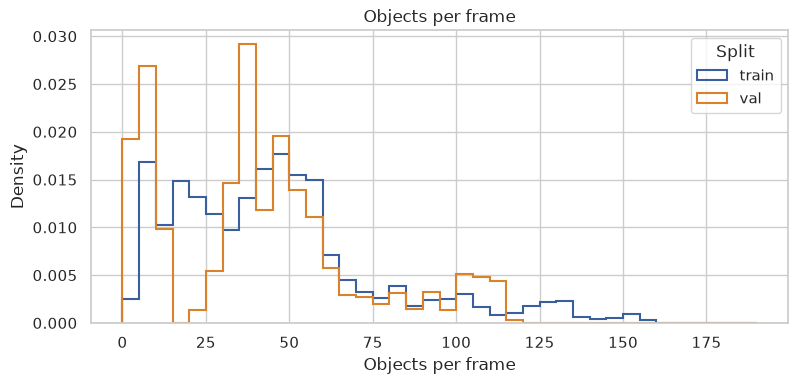

In [23]:
frame_counts = count_objects_per_frame(images, objects)
frame_count_summary = (
    summarize_quantiles(frame_counts, "objects", ["split"], QUANTILES)
    .join(
        frame_counts.group_by("split").agg(
            pl.col("objects").max().alias("max"), (pl.col("objects") == 0).sum().alias("empty")
        ),
        on="split",
    )
    .with_columns(pl.col("mean").round(1))
)
with pl.Config(tbl_cols=-1):
    display(frame_count_summary)
fig, ax = plt.subplots(figsize=(9, 3.8))
for split, color in SPLIT_COLORS.items():
    values = frame_counts.filter(pl.col("split") == split)["objects"].to_numpy()
    ax.hist(values, bins=list(range(0, 195, 5)), density=True, histtype="step", linewidth=1.5,
            color=color, label=split)
ax.set(xlabel="Objects per frame", ylabel="Density", title="Objects per frame")
ax.legend(title="Split")
plt.show()

- Objects per frame in `train`: mean 45.6, median 43, 95th percentile 118, max 180; 3 frames without objects.
- Objects per frame in `val`: mean 40.6, median 38, 95th percentile 104, max 116; no frame without objects.

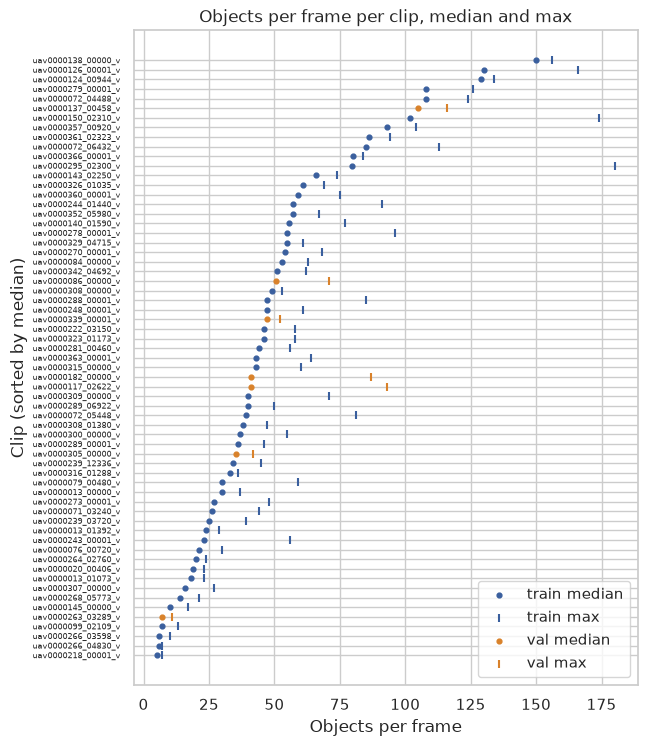

split,clip_median_min,clip_median_median,clip_median_max,clip_max_max
str,f64,f64,f64,u32
"""train""",5.0,43.5,150.0,180
"""val""",7.0,41.0,105.0,116


In [24]:
clip_density = (
    frame_counts.group_by("split", "clip")
    .agg(pl.col("objects").median().alias("median"), pl.col("objects").max().alias("max"))
    .sort("median")
)
fig, ax = plt.subplots(figsize=(6.5, 8.5))
for split, color in SPLIT_COLORS.items():
    rows = clip_density.with_row_index("position").filter(pl.col("split") == split)
    ax.scatter(rows["median"], rows["position"], color=color, s=12, label=f"{split} median")
    ax.scatter(rows["max"], rows["position"], color=color, marker="|", s=40,
               label=f"{split} max")
ax.set_yticks(range(clip_density.height), clip_density["clip"].to_list(), fontsize=5.5)
ax.set(xlabel="Objects per frame", ylabel="Clip (sorted by median)",
       title="Objects per frame per clip, median and max")
ax.legend(loc="lower right")
plt.show()
display(
    clip_density.group_by("split")
    .agg(
        pl.col("median").min().alias("clip_median_min"),
        pl.col("median").median().alias("clip_median_median"),
        pl.col("median").max().alias("clip_median_max"),
        pl.col("max").max().alias("clip_max_max"),
    )
    .sort("split")
)

- Clip medians of objects per frame: 5 to 150 in `train` (median over clips 43.5), 7 to 105 in `val` (median over clips 41).
- Densest clips by median: `uav0000138_00000_v` (150) in `train`, `uav0000137_00458_v` (105) in `val`; sparsest: `uav0000218_00001_v` (5) and `uav0000263_03289_v` (7).

### 6.2 Frames above query and submission limits

In [25]:
DENSITY_LIMITS = (100, 300, 500)
frame_counts.group_by("split").agg(
    pl.len().alias("frames"),
    *(
        expression
        for limit in DENSITY_LIMITS
        for expression in (
            (pl.col("objects") > limit).sum().alias(f"frames_above_{limit}"),
            (pl.col("objects") > limit).mean().round(4).alias(f"share_above_{limit}"),
        )
    ),
).sort("split")

split,frames,frames_above_100,share_above_100,frames_above_300,share_above_300,frames_above_500,share_above_500
str,u32,u32,f64,u32,f64,u32,f64
"""train""",24454,1851,0.0757,0,0.0,0,0.0
"""val""",2593,183,0.0706,0,0.0,0,0.0


- Frames with more than 100 objects: 1,851 of 24,454 (7.57%) in `train`, 183 of 2,593 (7.06%) in `val`.
- No frame has more than 300 objects in either split; the maximum is 180.

### 6.3 Overlap between objects

For each object, the largest IoU with another labelled object of the same frame, over all classes and within its own class.

In [26]:
IOU_LIMITS = (0.0, 0.3, 0.5)
object_overlaps = add_max_iou_columns(objects).join(build_class_table(), on="class_id")
object_overlaps = pl.concat(
    [
        object_overlaps.with_columns(pl.lit("all").alias("class_name")),
        object_overlaps,
    ]
).with_columns(pl.col("class_name").cast(CLASS_ORDER))
overlap_shares = (
    object_overlaps.group_by("split", "class_name")
    .agg(
        (pl.col(f"max_iou_{scope}") > limit).mean().alias(f"{scope}_iou_above_{limit}")
        for scope in ("any_class", "same_class")
        for limit in IOU_LIMITS
    )
    .sort("split", "class_name")
    .with_columns(pl.selectors.float().round(3))
)
with pl.Config(tbl_rows=-1, tbl_cols=-1):
    display(overlap_shares)

split,class_name,any_class_iou_above_0.0,any_class_iou_above_0.3,any_class_iou_above_0.5,same_class_iou_above_0.0,same_class_iou_above_0.3,same_class_iou_above_0.5
str,enum,f64,f64,f64,f64,f64,f64
"""train""","""all""",0.606,0.146,0.034,0.398,0.069,0.014
"""train""","""person""",0.672,0.23,0.064,0.442,0.115,0.033
"""train""","""bicycle""",0.747,0.317,0.064,0.19,0.028,0.002
"""train""","""car""",0.561,0.071,0.008,0.485,0.065,0.007
"""train""","""van""",0.482,0.05,0.006,0.138,0.001,0.0
"""train""","""truck""",0.596,0.06,0.012,0.264,0.035,0.008
"""train""","""tricycle""",0.637,0.107,0.014,0.205,0.021,0.003
"""train""","""bus""",0.593,0.018,0.0,0.015,0.0,0.0
"""train""","""motor""",0.62,0.281,0.082,0.171,0.027,0.006


- Objects overlapping another object (IoU > 0), any class: 60.6% in `train`, 61.3% in `val`; IoU > 0.3: 14.6% and 20.6%; IoU > 0.5: 3.4% and 6.9%.
- Same class only: IoU > 0.3 for 6.9% (`train`) and 8.1% (`val`); IoU > 0.5 for 1.4% and 1.8%.
- Highest shares with IoU > 0.5, any class: motor 8.2%, person 6.4%, bicycle 6.4% in `train`; bicycle 25.5%, motor 9.3%, person 9.1% in `val`.
- Highest same-class share with IoU > 0.5: person, 3.3% in `train` and 3.6% in `val`.

## 7. Ignored regions

Ignored regions are the unique `iscrowd=1` boxes. Coverage is the area of their union divided by the frame or box area, so overlapping regions count once (`src.data.boxes.compute_covered_fraction`).

### 7.1 Frames and frame coverage

In [27]:
regions_per_frame = (
    images.select("split", "image_id", "clip", "width", "height")
    .join(
        ignored.group_by("split", "image_id").len("regions"),
        on=["split", "image_id"],
        how="left",
    )
    .with_columns(pl.col("regions").fill_null(0))
)
frame_coverage = add_ignored_coverage_column(
    regions_per_frame.with_columns(
        pl.lit(0).alias("x"), pl.lit(0).alias("y"), pl.col("width").alias("w"),
        pl.col("height").alias("h"),
    ),
    ignored,
).rename({"ignored_fraction": "covered_fraction"})


def summarize_ignored_frames(by: list[str]) -> pl.DataFrame:
    return (
        frame_coverage.group_by(by)
        .agg(
            pl.len().alias("frames"),
            (pl.col("regions") > 0).mean().alias("share_with_regions"),
            pl.col("regions").mean().alias("regions_mean"),
            pl.col("regions").max().alias("regions_max"),
            pl.col("covered_fraction").mean().alias("covered_mean"),
            pl.col("covered_fraction").quantile(0.95, "linear").alias("covered_p95"),
            pl.col("covered_fraction").max().alias("covered_max"),
        )
        .with_columns(pl.selectors.float().round(3))
        .sort(by)
    )


with pl.Config(tbl_cols=-1):
    display(summarize_ignored_frames(["split"]))

split,frames,share_with_regions,regions_mean,regions_max,covered_mean,covered_p95,covered_max
str,u32,f64,f64,u32,f64,f64,f64
"""train""",24454,0.719,2.573,22,0.023,0.099,0.38
"""val""",2593,0.752,1.893,7,0.02,0.085,0.103


- Frames with at least one ignored region: 71.9% in `train`, 75.2% in `val`.
- Regions per frame: mean 2.57, max 22 in `train`; mean 1.89, max 7 in `val`.
- Share of frame area covered: mean 2.3%, 95th percentile 9.9%, max 38.0% in `train`; mean 2.0%, 95th percentile 8.5%, max 10.3% in `val`.

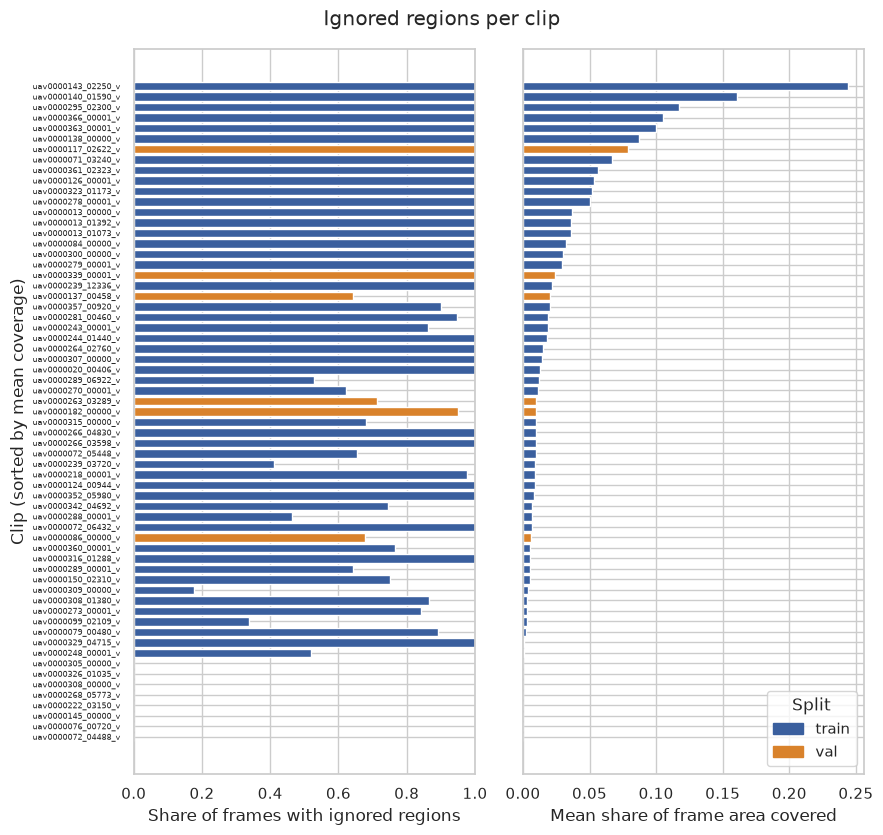

In [28]:
clip_ignored = summarize_ignored_frames(["split", "clip"]).sort("covered_mean")
fig, axes = plt.subplots(1, 2, figsize=(9, 8.5), sharey=True)
positions = range(clip_ignored.height)
bar_colors = [SPLIT_COLORS[split] for split in clip_ignored["split"]]
axes[0].barh(positions, clip_ignored["share_with_regions"], color=bar_colors)
axes[0].set(xlabel="Share of frames with ignored regions", xlim=(0, 1),
            ylabel="Clip (sorted by mean coverage)")
axes[1].barh(positions, clip_ignored["covered_mean"], color=bar_colors)
axes[1].set(xlabel="Mean share of frame area covered")
axes[0].set_yticks(positions, clip_ignored["clip"].to_list(), fontsize=5.5)
axes[1].legend(
    handles=[plt.Rectangle((0, 0), 1, 1, color=color) for color in SPLIT_COLORS.values()],
    labels=list(SPLIT_COLORS), title="Split", loc="lower right",
)
fig.suptitle("Ignored regions per clip")
fig.tight_layout()
plt.show()

- Clips without any ignored region: 7 of 56 in `train`, 1 of 7 in `val` (`uav0000305_00000_v`).
- Highest mean coverage: 24.4% in `train` (`uav0000143_02250_v`), 7.9% in `val` (`uav0000117_02622_v`).

### 7.2 True ignored regions and VisDrone "others"

`orig_category_id` 0 is a VisDrone ignored region, 11 is VisDrone "others".

In [29]:
ignored_by_category = (
    ignored.join(images.select("split", "image_id", "clip", "width", "height"),
                 on=["split", "image_id"])
    .group_by("split", "orig_category_id")
    .agg(
        pl.len().alias("regions"),
        pl.col("image_id").n_unique().alias("frames"),
        pl.col("clip").n_unique().alias("clips"),
        pl.col("area").sqrt().median().round(1).alias("sqrt_area_p50"),
        (pl.col("area") / (pl.col("width") * pl.col("height"))).median().round(4)
        .alias("frame_share_p50"),
    )
    .with_columns((pl.col("regions") / pl.col("regions").sum().over("split")).round(3)
                  .alias("region_share"))
    .sort("split", "orig_category_id")
)
ignored_by_category

split,orig_category_id,regions,frames,clips,sqrt_area_p50,frame_share_p50,region_share
str,i64,u32,u32,u32,f64,f64,f64
"""train""",0,61685,17226,47,93.8,0.0044,0.98
"""train""",11,1244,1244,8,77.0,0.003,0.02
"""val""",0,4678,1811,6,104.7,0.0062,0.953
"""val""",11,231,140,2,110.5,0.006,0.047


- `train`: 61,685 ignored regions (98.0%) in 47 clips and 1,244 "others" (2.0%) in 8 clips.
- `val`: 4,678 ignored regions (95.3%) in 6 clips and 231 "others" (4.7%) in 2 clips.
- Median region √area: 93.8 px (ignored) and 77.0 px (others) in `train`; median share of the frame per region 0.44% and 0.30%.

### 7.3 Labelled objects inside ignored regions

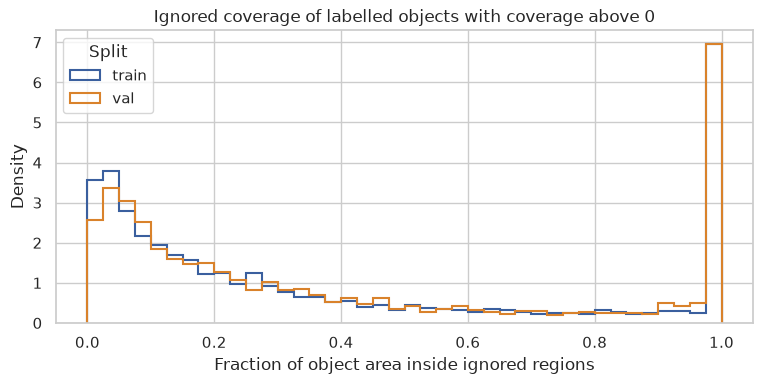

In [30]:
object_coverage = add_ignored_coverage_column(objects, ignored).join(
    build_class_table(), on="class_id"
)
covered_objects = object_coverage.filter(pl.col("ignored_fraction") > 0)
fig, ax = plt.subplots(figsize=(9, 3.8))
for split, color in SPLIT_COLORS.items():
    values = covered_objects.filter(pl.col("split") == split)["ignored_fraction"].to_numpy()
    ax.hist(values, bins=list(np.linspace(0, 1, 41)), density=True, histtype="step",
            linewidth=1.5, color=color, label=split)
ax.set(xlabel="Fraction of object area inside ignored regions", ylabel="Density",
       title="Ignored coverage of labelled objects with coverage above 0")
ax.legend(title="Split")
plt.show()

In [31]:
coverage_shares = (
    pl.concat([object_coverage.with_columns(pl.lit("all").alias("class_name")), object_coverage])
    .with_columns(pl.col("class_name").cast(CLASS_ORDER))
    .group_by("split", "class_name")
    .agg(
        pl.len().alias("objects"),
        (pl.col("ignored_fraction") > 0).mean().alias("share_above_0"),
        (pl.col("ignored_fraction") > 0.5).mean().alias("share_above_0.5"),
        (pl.col("ignored_fraction") == 1).mean().alias("share_fully_inside"),
        (pl.col("ignored_fraction") > 0.5).sum().alias("objects_above_0.5"),
    )
    .with_columns(pl.selectors.float().round(4))
    .sort("split", "class_name")
)
with pl.Config(tbl_rows=-1, tbl_cols=-1):
    display(coverage_shares)

split,class_name,objects,share_above_0,share_above_0.5,share_fully_inside,objects_above_0.5
str,enum,u32,f64,f64,f64,u32
"""train""","""all""",1114408,0.0348,0.0107,0.006,11932
"""train""","""person""",330685,0.0303,0.0135,0.0078,4449
"""train""","""bicycle""",40114,0.0232,0.0195,0.0172,782
"""train""","""car""",512470,0.0398,0.0095,0.0049,4881
"""train""","""van""",48623,0.0569,0.0112,0.0039,545
"""train""","""truck""",29168,0.0461,0.006,0.0028,174
"""train""","""tricycle""",41859,0.022,0.011,0.0062,461
"""train""","""bus""",8896,0.0978,0.0042,0.0007,37
"""train""","""motor""",102593,0.0148,0.0059,0.0033,603


- Labelled objects overlapping an ignored region: 3.48% in `train`, 3.60% in `val`; more than half covered: 1.07% (11,932 objects) and 1.16% (1,216 objects); fully inside: 0.60% in both.
- Highest share more than half covered: bicycle 1.95% in `train`, tricycle 4.44% in `val`.
- No `val` bus overlaps an ignored region.

## 8. Occlusion and truncation

VisDrone annotation levels ([VisDrone toolkit format](https://github.com/VisDrone/VisDrone2018-VID-toolkit)): occlusion 0 none, 1 partial (1% to 50% occluded), 2 heavy (50% to 100%); truncation 0 none, 1 partial (1% to 50% outside the frame).

### 8.1 Occlusion per class

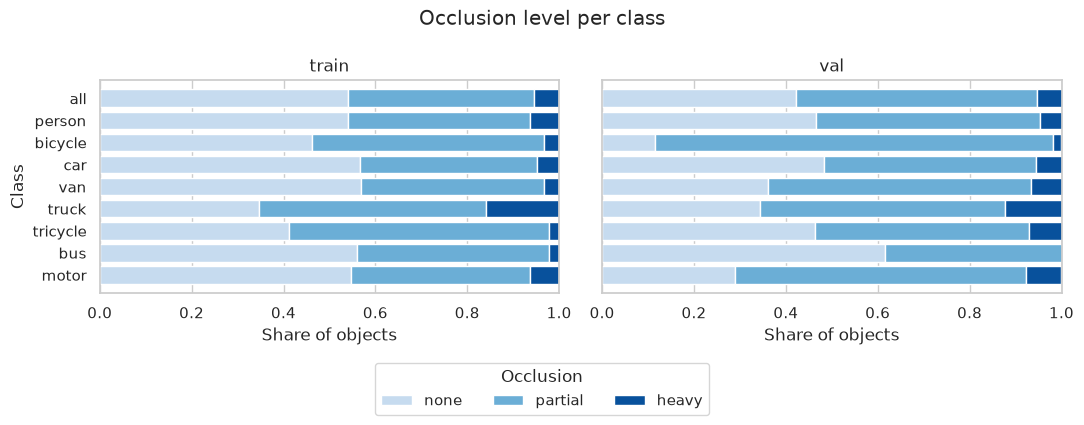

split,class_name,none,partial,heavy
str,enum,f64,f64,f64
"""train""","""all""",0.541,0.404,0.055
"""train""","""person""",0.54,0.397,0.063
"""train""","""bicycle""",0.463,0.503,0.034
"""train""","""car""",0.566,0.385,0.049
"""train""","""van""",0.569,0.399,0.032
"""train""","""truck""",0.346,0.495,0.159
"""train""","""tricycle""",0.412,0.567,0.021
"""train""","""bus""",0.561,0.417,0.023
"""train""","""motor""",0.546,0.391,0.063


In [32]:
OCCLUSION_LEVELS = list(OCCLUSION_COLORS)
occlusion_shares = (
    object_shapes_with_all.with_columns(
        pl.col("occlusion").replace_strict(dict(enumerate(OCCLUSION_LEVELS))).alias("level")
    )
    .group_by("split", "class_name", "level")
    .len()
    .with_columns((pl.col("len") / pl.col("len").sum().over("split", "class_name")).round(3))
    .pivot(on="level", index=["split", "class_name"], values="len")
    .select("split", "class_name", *OCCLUSION_LEVELS)
    .fill_null(0)
    .sort("split", "class_name")
)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, split in zip(axes, SPLIT_COLORS):
    rows = occlusion_shares.filter(pl.col("split") == split)
    names = rows["class_name"].cast(pl.String).to_list()
    left = np.zeros(rows.height)
    for level, color in OCCLUSION_COLORS.items():
        ax.barh(names, rows[level], left=left, color=color, label=level)
        left += rows[level].to_numpy()
    ax.set(xlabel="Share of objects", xlim=(0, 1), title=split)
axes[0].set_ylabel("Class")
axes[0].invert_yaxis()
fig.legend(*axes[0].get_legend_handles_labels(), title="Occlusion", ncol=3,
           loc="upper center", bbox_to_anchor=(0.5, 0.02))
fig.suptitle("Occlusion level per class")
fig.tight_layout()
plt.show()
with pl.Config(tbl_rows=-1):
    display(occlusion_shares)

- All classes, none / partial / heavy: 54.1% / 40.4% / 5.5% in `train`, 42.2% / 52.5% / 5.4% in `val`.
- Highest heavy share: truck 15.9% in `train`, truck 12.4% in `val`.
- Lowest unoccluded share: truck 34.6% in `train`; bicycle 11.6%, motor 29.0%, truck 34.4% in `val`. `val` bus is 61.5% unoccluded.

### 8.2 Truncation per class

In [33]:
truncation_shares = (
    object_shapes_with_all.group_by("split", "class_name")
    .agg(
        pl.len().alias("objects"),
        (pl.col("truncation") == 1).sum().alias("truncated"),
        (pl.col("truncation") == 1).mean().round(4).alias("truncated_share"),
    )
    .sort("split", "class_name")
)
with pl.Config(tbl_rows=-1):
    display(truncation_shares)

split,class_name,objects,truncated,truncated_share
str,enum,u32,u32,f64
"""train""","""all""",1114408,49777,0.0447
"""train""","""person""",330685,6437,0.0195
"""train""","""bicycle""",40114,336,0.0084
"""train""","""car""",512470,30414,0.0593
"""train""","""van""",48623,2960,0.0609
"""train""","""truck""",29168,3515,0.1205
"""train""","""tricycle""",41859,1907,0.0456
"""train""","""bus""",8896,985,0.1107
"""train""","""motor""",102593,3223,0.0314


- Truncated objects: 4.47% in `train` (49,777), 3.56% in `val` (3,746).
- Highest truncated shares: truck 12.1% and bus 11.1% in `train`; bus 36.5% (373 instances) and motor 4.2% in `val`.

### 8.3 Object size by occlusion level

In [34]:
size_by_occlusion = (
    object_shapes.with_columns(
        pl.col("occlusion").replace_strict(dict(enumerate(OCCLUSION_LEVELS))).alias("level")
    )
    .group_by("split", "level")
    .agg(
        pl.len().alias("objects"),
        pl.col("sqrt_area").median().round(1).alias("sqrt_area_p50"),
        is_in_size_bucket(pl.col("area"), "small").mean().round(3).alias("small_share"),
    )
    .sort("split", pl.col("level").replace_strict({v: k for k, v in enumerate(OCCLUSION_LEVELS)}))
)
size_by_occlusion

split,level,objects,sqrt_area_p50,small_share
str,str,u32,f64,f64
"""train""","""none""",603130,43.4,0.301
"""train""","""partial""",450421,47.5,0.188
"""train""","""heavy""",60857,48.7,0.171
"""val""","""none""",44387,56.8,0.165
"""val""","""partial""",55200,52.8,0.203
"""val""","""heavy""",5653,37.3,0.364


- `train` median √area by occlusion none / partial / heavy: 43.4 / 47.5 / 48.7 px; small share 30.1% / 18.8% / 17.1%.
- `val` median √area: 56.8 / 52.8 / 37.3 px; small share 16.5% / 20.3% / 36.4%.

## 9. Temporal structure

Tracks are identified by (`split`, `clip`, `track_id`). For each object at frame $t$ and the same track at $t + k$: center displacement in px, displacement relative to $\sqrt{\text{area}}$ at $t$, and IoU of the two boxes. Pairs exist only where the track is labelled in both frames. Displacement includes camera motion.

### 9.1 Change between frames $t$ and $t + k$

In [35]:
OFFSETS = (1, 2, 5, 10)
tracked_objects = objects.join(
    images.select("split", "image_id", "clip", "frame_id"), on=["split", "image_id"]
)
track_pairs = pl.concat([pair_track_boxes(tracked_objects, k) for k in range(1, 11)])
offset_summary = (
    track_pairs.filter(pl.col("offset").is_in(OFFSETS))
    .group_by("split", "offset")
    .agg(
        pl.len().alias("pairs"),
        pl.col("displacement").median().alias("displacement_p50"),
        pl.col("displacement").quantile(0.9, "linear").alias("displacement_p90"),
        pl.col("relative_displacement").median().alias("relative_p50"),
        pl.col("relative_displacement").quantile(0.9, "linear").alias("relative_p90"),
        pl.col("iou").median().alias("iou_p50"),
        pl.col("iou").quantile(0.1, "linear").alias("iou_p10"),
        (pl.col("iou") >= 0.5).mean().alias("iou_at_least_0.5"),
        (pl.col("iou") >= 0.7).mean().alias("iou_at_least_0.7"),
    )
    .with_columns(pl.selectors.float().round(3))
    .sort("split", "offset")
)
with pl.Config(tbl_cols=-1):
    display(offset_summary)

split,offset,pairs,displacement_p50,displacement_p90,relative_p50,relative_p90,iou_p50,iou_p10,iou_at_least_0.5,iou_at_least_0.7
str,i32,u32,f64,f64,f64,f64,f64,f64,f64,f64
"""train""",1,1106507,2.0,10.0,0.044,0.18,0.897,0.65,0.957,0.862
"""train""",2,1098945,3.905,19.526,0.085,0.356,0.81,0.428,0.859,0.672
"""train""",5,1076433,9.434,47.901,0.209,0.884,0.598,0.078,0.595,0.399
"""train""",10,1039864,18.682,91.166,0.415,1.733,0.358,0.0,0.396,0.262
"""val""",1,104405,2.693,16.125,0.056,0.275,0.868,0.501,0.901,0.778
"""val""",2,103602,5.099,31.5,0.108,0.539,0.759,0.234,0.773,0.582
"""val""",5,101239,13.0,74.002,0.265,1.287,0.506,0.0,0.505,0.308
"""val""",10,97411,25.48,134.183,0.523,2.375,0.242,0.0,0.302,0.153


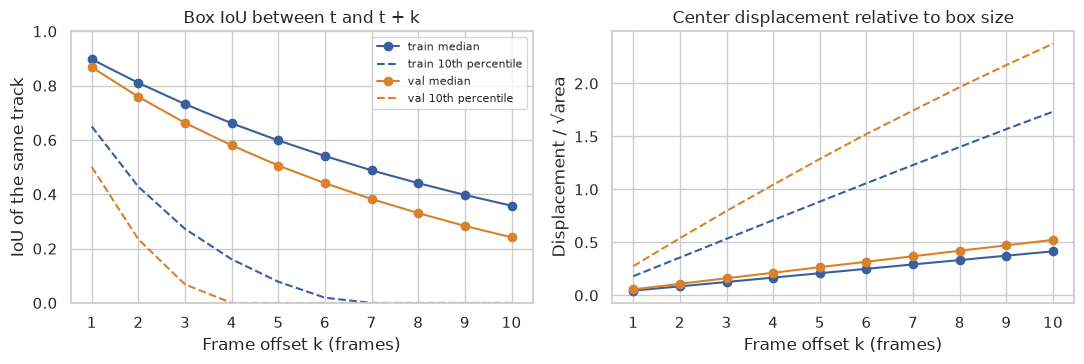

In [36]:
offset_curve = (
    track_pairs.group_by("split", "offset")
    .agg(
        pl.col("iou").median().alias("iou_p50"),
        pl.col("iou").quantile(0.1, "linear").alias("iou_p10"),
        pl.col("relative_displacement").median().alias("relative_p50"),
        pl.col("relative_displacement").quantile(0.9, "linear").alias("relative_p90"),
    )
    .sort("split", "offset")
)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for split, color in SPLIT_COLORS.items():
    rows = offset_curve.filter(pl.col("split") == split)
    axes[0].plot(rows["offset"], rows["iou_p50"], color=color, marker="o", label=f"{split} median")
    axes[0].plot(rows["offset"], rows["iou_p10"], color=color, linestyle="--",
                 label=f"{split} 10th percentile")
    axes[1].plot(rows["offset"], rows["relative_p50"], color=color, marker="o",
                 label=f"{split} median")
    axes[1].plot(rows["offset"], rows["relative_p90"], color=color, linestyle="--",
                 label=f"{split} 90th percentile")
axes[0].set(xlabel="Frame offset k (frames)", ylabel="IoU of the same track", ylim=(0, 1),
            title="Box IoU between t and t + k")
axes[1].set(xlabel="Frame offset k (frames)", ylabel="Displacement / √area",
            title="Center displacement relative to box size")
for ax in axes:
    ax.set_xticks(range(1, 11))
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

| k (frames) | 1 | 2 | 5 | 10 |
| --- | --- | --- | --- | --- |
| median IoU, `train` | 0.897 | 0.810 | 0.598 | 0.358 |
| median IoU, `val` | 0.868 | 0.759 | 0.506 | 0.242 |
| pairs with IoU ≥ 0.5, `train` | 95.7% | 85.9% | 59.5% | 39.6% |
| pairs with IoU ≥ 0.5, `val` | 90.1% | 77.3% | 50.5% | 30.2% |
| median displacement, `train` (px) | 2.0 | 3.9 | 9.4 | 18.7 |
| median displacement / √area, `train` | 0.044 | 0.085 | 0.209 | 0.415 |
| median displacement / √area, `val` | 0.056 | 0.108 | 0.265 | 0.523 |

- 10th percentile IoU at k = 5: 0.078 in `train`, 0.0 in `val`.

In [37]:
FRAME_STEP_CANDIDATE = 5
class_offset_summary = (
    track_pairs.filter(pl.col("offset") == FRAME_STEP_CANDIDATE)
    .join(build_class_table(), on="class_id")
    .with_columns(pl.col("class_name").cast(CLASS_ORDER))
    .group_by("split", "class_name")
    .agg(
        pl.len().alias("pairs"),
        pl.col("displacement").median().alias("displacement_p50"),
        pl.col("relative_displacement").median().alias("relative_p50"),
        pl.col("iou").median().alias("iou_p50"),
        (pl.col("iou") >= 0.5).mean().alias("iou_at_least_0.5"),
    )
    .with_columns(pl.selectors.float().round(3))
    .sort("split", "class_name")
)
with pl.Config(tbl_rows=-1):
    display(class_offset_summary)

split,class_name,pairs,displacement_p50,relative_p50,iou_p50,iou_at_least_0.5
str,enum,u32,f64,f64,f64,f64
"""train""","""person""",317121,10.63,0.304,0.46,0.46
"""train""","""bicycle""",38557,13.21,0.334,0.447,0.442
"""train""","""car""",497092,8.062,0.152,0.686,0.689
"""train""","""van""",47294,7.071,0.137,0.718,0.715
"""train""","""truck""",28423,7.28,0.108,0.756,0.768
"""train""","""tricycle""",40441,10.44,0.207,0.598,0.613
"""train""","""bus""",8636,14.221,0.13,0.735,0.869
"""train""","""motor""",98869,10.817,0.309,0.473,0.478
"""val""","""person""",46629,10.062,0.24,0.492,0.493


- At k = 5, median IoU in `train` ranges from 0.447 (bicycle) and 0.460 (person) to 0.756 (truck); in `val` from 0.296 (bicycle) and 0.322 (motor) to 0.795 (bus).
- Median displacement / √area at k = 5: person 0.304, bicycle 0.334, motor 0.309, car 0.152 in `train`; bicycle 0.510, motor 0.466 in `val`.

### 9.2 Track length

split,tracks,tracks_with_class_change,tracks_with_gaps,frames_p50,frames_max
str,u32,u32,u32,f64,u32
"""train""",7354,153,508,104.0,1255
"""val""",746,8,84,115.0,637


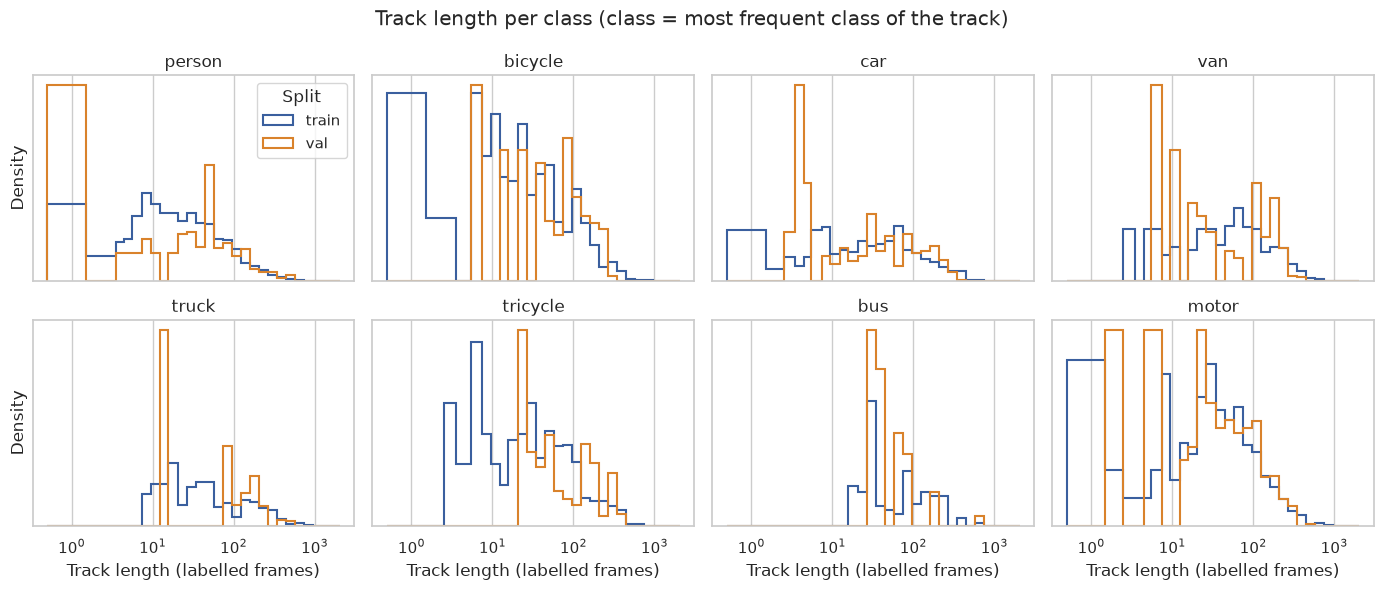

split,class_name,count,mean,p5,p25,p50,p75,p95
str,enum,u32,f64,f64,f64,f64,f64,f64
"""train""","""person""",2620,126.2,9.0,36.0,85.0,178.0,401.1
"""train""","""bicycle""",294,131.8,9.6,40.2,103.0,169.8,398.0
"""train""","""car""",2983,171.9,13.0,61.0,126.0,247.5,421.0
"""train""","""van""",267,181.6,23.3,72.5,147.0,249.0,426.0
"""train""","""truck""",141,209.1,18.0,73.0,175.0,272.0,616.0
"""train""","""tricycle""",278,151.9,10.0,49.2,98.0,228.8,393.4
"""train""","""bus""",47,181.0,31.9,89.5,157.0,214.0,421.0
"""train""","""motor""",724,143.2,15.0,48.0,98.5,196.0,398.8
"""val""","""person""",329,146.9,13.6,49.0,104.0,207.0,464.0


In [38]:
tracks = summarize_tracks(tracked_objects)
display(
    tracks.group_by("split")
    .agg(
        pl.len().alias("tracks"),
        (pl.col("class_count") > 1).sum().alias("tracks_with_class_change"),
        pl.col("has_gap").sum().alias("tracks_with_gaps"),
        pl.col("frames").median().alias("frames_p50"),
        pl.col("frames").max().alias("frames_max"),
    )
    .sort("split")
)
fig = plot_class_histograms(
    tracks, "frames", np.unique(np.round(np.geomspace(1, 2048, 31))) - 0.5,
    "Track length (labelled frames)",
    "Track length per class (class = most frequent class of the track)",
)
plt.show()
track_lengths = summarize_quantiles(
    tracks.join(build_class_table(), on="class_id").with_columns(
        pl.col("class_name").cast(CLASS_ORDER)
    ),
    "frames",
    ["split", "class_name"],
    QUANTILES,
).with_columns(pl.selectors.float().round(1))
with pl.Config(tbl_rows=-1, tbl_cols=-1):
    display(track_lengths)

- Tracks: 7,354 in `train`, 746 in `val`; median length 104 and 115 labelled frames; maximum 1,255 and 637.
- Tracks whose class changes: 153 in `train`, 8 in `val`; tracks with gaps: 508 and 84.
- Median track length per class in `train`: person 85, tricycle 98, motor 98.5, bicycle 103, car 126, van 147, bus 157, truck 175 frames.
- `val` has 6 bus tracks and 15 truck tracks.

## 10. Sample frames

Nine clips chosen from the statistics above to cover all `train` and `val` frame sizes, sparse and dense clips, heavy ignored coverage, and rare classes. Each figure shows the middle frame among the clip frames that contain its focus class, GT boxes colored by class, shaded ignored regions, and a crop of a quarter of the frame width and height placed where it holds the most objects smaller than the frame's median object area (`src.visualization.frames`). Figures are JPEG to keep the notebook small.

In [39]:
SAMPLE_CLIPS = pl.DataFrame(
    [
        ("uav0000086_00000_v", "person", "val clip with 96% person"),
        ("uav0000278_00001_v", "car", "only 1360 × 765 train clip"),
        ("uav0000263_03289_v", "truck", "sparse clip with the largest bus share"),
        ("uav0000305_00000_v", "bus", "val clip with bus, side view"),
        ("uav0000244_01440_v", "car", "only 1920 × 1080 train clip"),
        ("uav0000138_00000_v", "person", "densest train clip"),
        ("uav0000143_02250_v", "car", "highest ignored coverage"),
        ("uav0000117_02622_v", "person", "2720 × 1530 val clip, highest val coverage"),
        ("uav0000268_05773_v", "car", "only 3840 × 2160 clip"),
    ],
    schema=["clip", "focus_class", "reason"],
    orient="row",
)
sample_overview = (
    SAMPLE_CLIPS.with_row_index("order")
    .join(clip_density.select("split", "clip", "median"), on="clip")
    .join(clip_ignored.select("clip", "frames", "covered_mean"), on="clip")
    .join(images.group_by("clip").agg(pl.col("width", "height").first()), on="clip")
    .join(
        clip_class_shares.unpivot(index="clip", on=CLASS_NAMES, variable_name="focus_class",
                                  value_name="focus_share"),
        on=["clip", "focus_class"],
    )
    .select("split", "clip", "width", "height", "frames", pl.col("median").alias("objects_p50"),
            "focus_class", pl.col("focus_share").round(3), "covered_mean", "reason",
            "order")
    .sort("order")
    .drop("order")
)
with pl.Config(tbl_cols=-1, fmt_str_lengths=60):
    display(sample_overview)

split,clip,width,height,frames,objects_p50,focus_class,focus_share,covered_mean,reason
str,str,i64,i64,u32,f64,str,f64,f64,str
"""val""","""uav0000086_00000_v""",1344,756,464,50.5,"""person""",0.957,0.006,"""val clip with 96% person"""
"""train""","""uav0000278_00001_v""",1360,765,962,55.0,"""car""",0.53,0.05,"""only 1360 × 765 train clip"""
"""val""","""uav0000263_03289_v""",1904,1071,725,7.0,"""truck""",0.354,0.01,"""sparse clip with the largest bus share"""
"""val""","""uav0000305_00000_v""",1904,1071,184,35.5,"""bus""",0.041,0.0,"""val clip with bus, side view"""
"""train""","""uav0000244_01440_v""",1920,1080,721,57.0,"""car""",0.545,0.018,"""only 1920 × 1080 train clip"""
"""train""","""uav0000138_00000_v""",2688,1512,213,150.0,"""person""",0.409,0.087,"""densest train clip"""
"""train""","""uav0000143_02250_v""",2688,1512,261,66.0,"""car""",0.539,0.244,"""highest ignored coverage"""
"""val""","""uav0000117_02622_v""",2720,1530,349,41.0,"""person""",0.56,0.079,"""2720 × 1530 val clip, highest val coverage"""
"""train""","""uav0000268_05773_v""",3840,2160,978,14.0,"""car""",0.64,0.0,"""only 3840 × 2160 clip"""


- The 9 clips cover all 7 `train` and `val` frame sizes, from 1344 × 756 to 3840 × 2160 px; 5 are `train` and 4 are `val` clips.
- Median objects per frame of the chosen clips ranges from 7 to 150; mean ignored coverage from 0 to 24.4% of the frame.

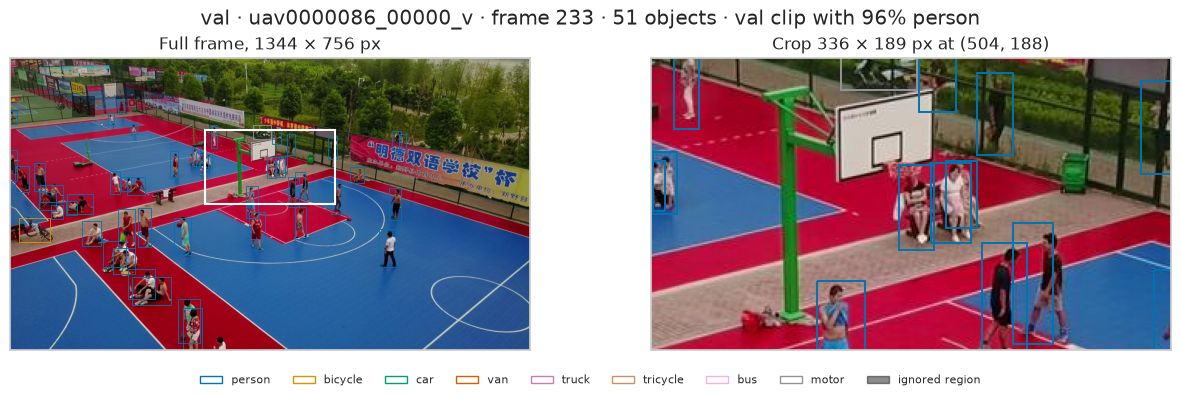

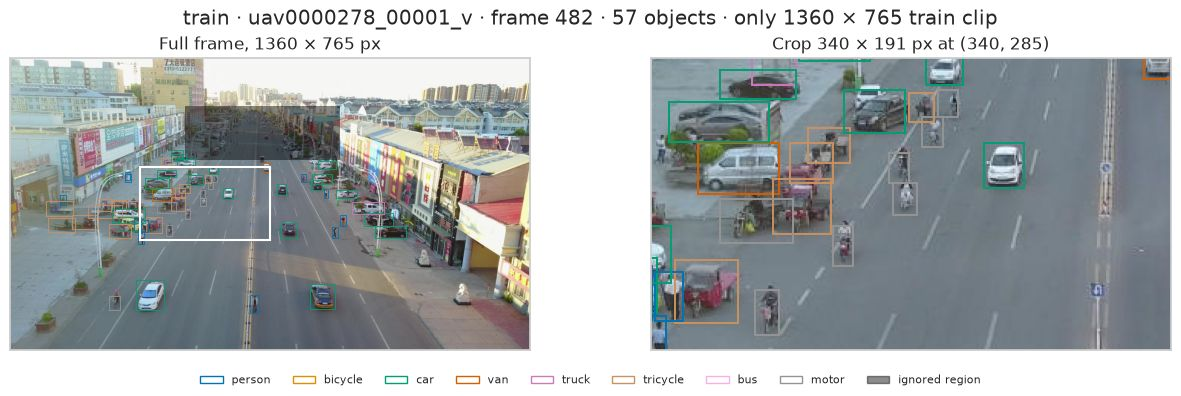

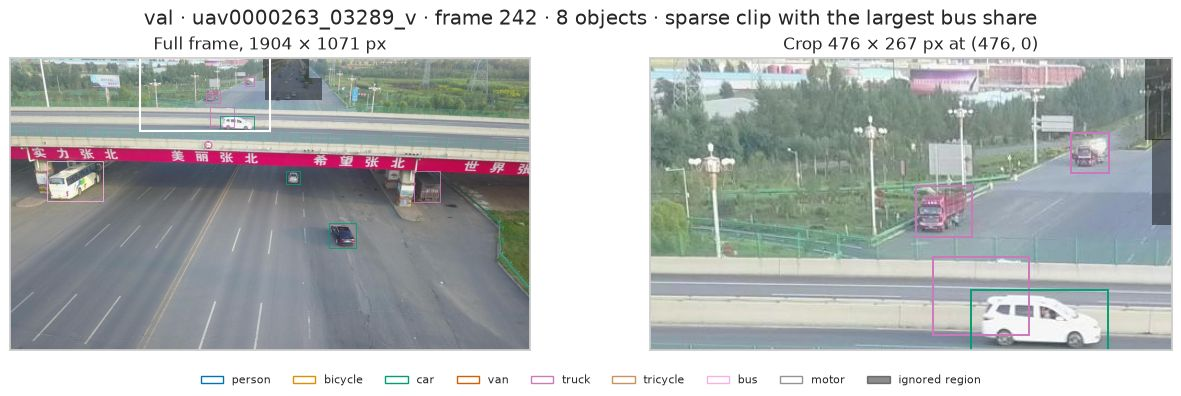

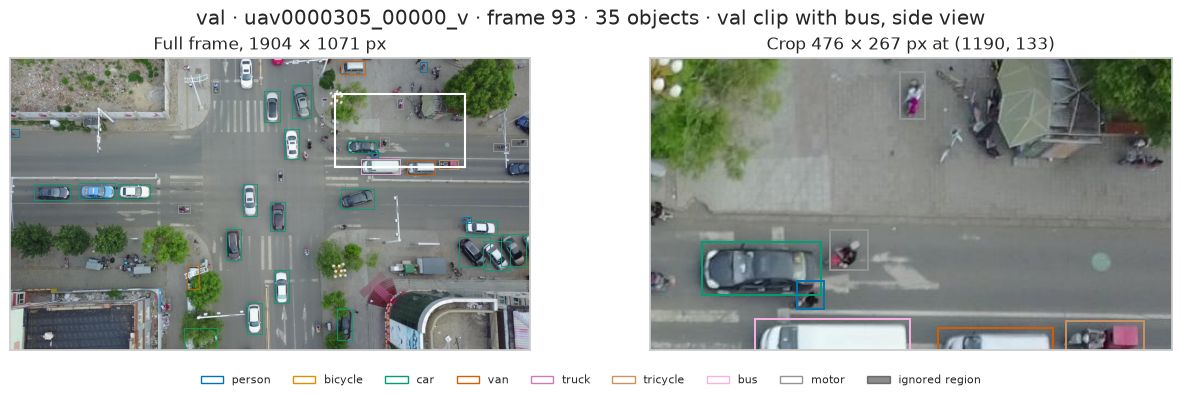

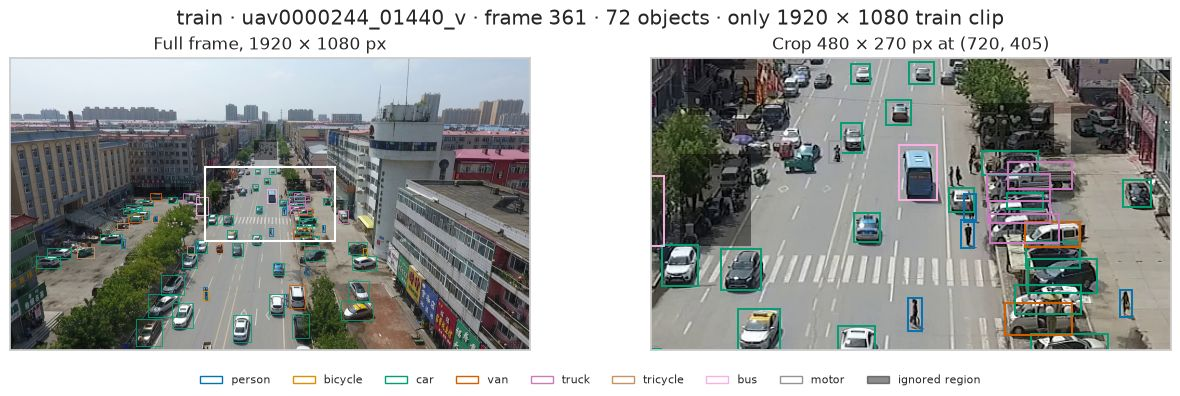

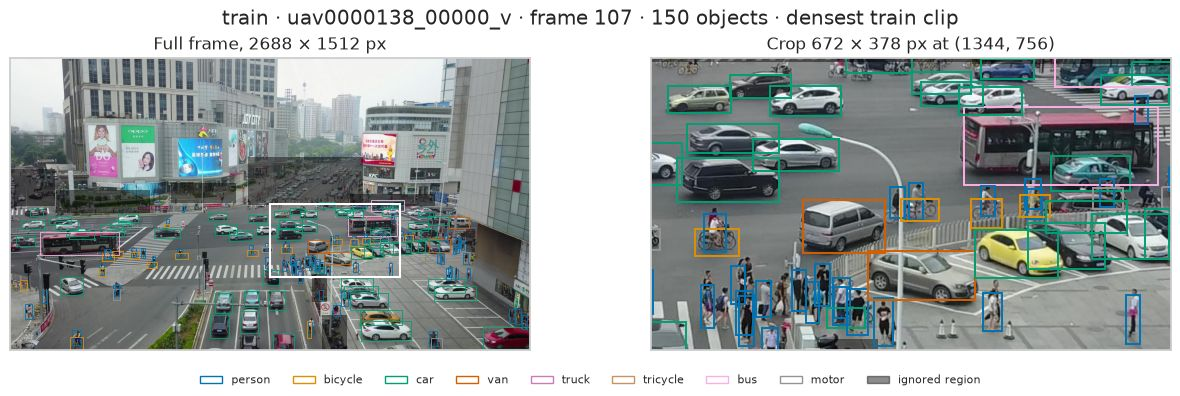

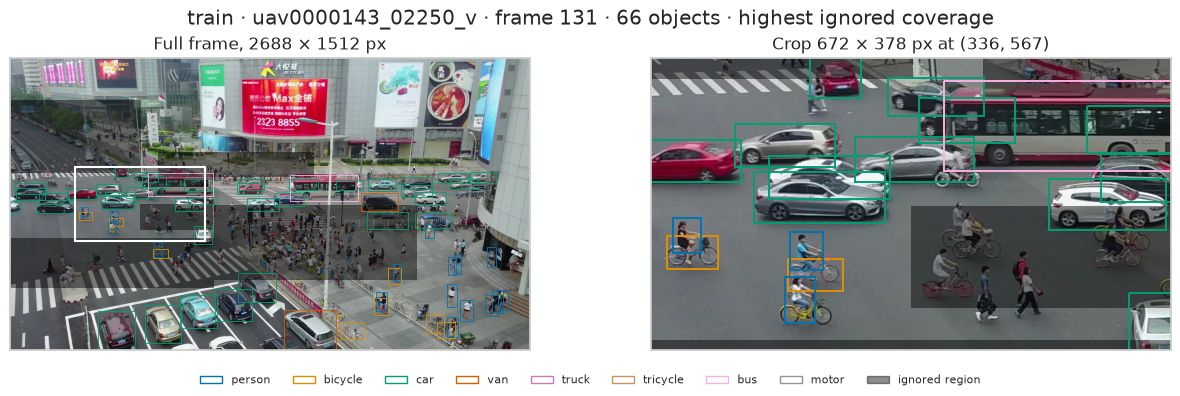

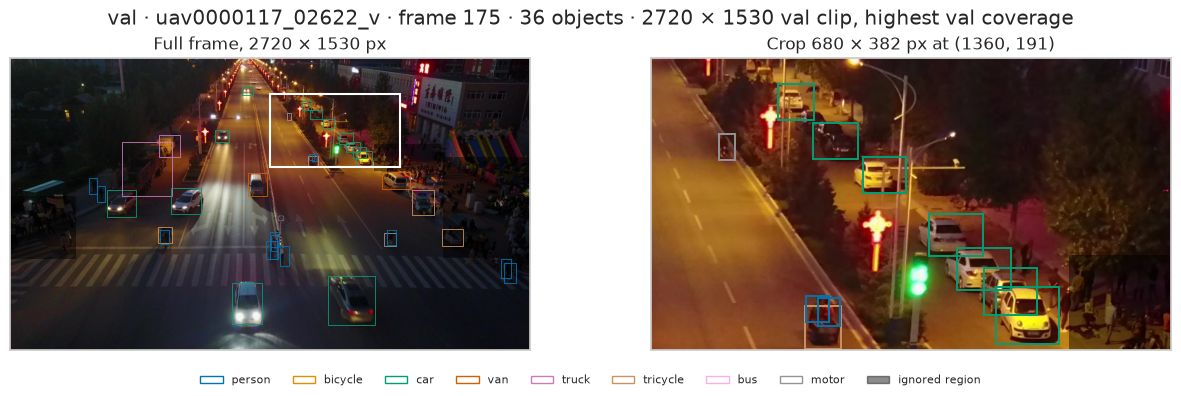

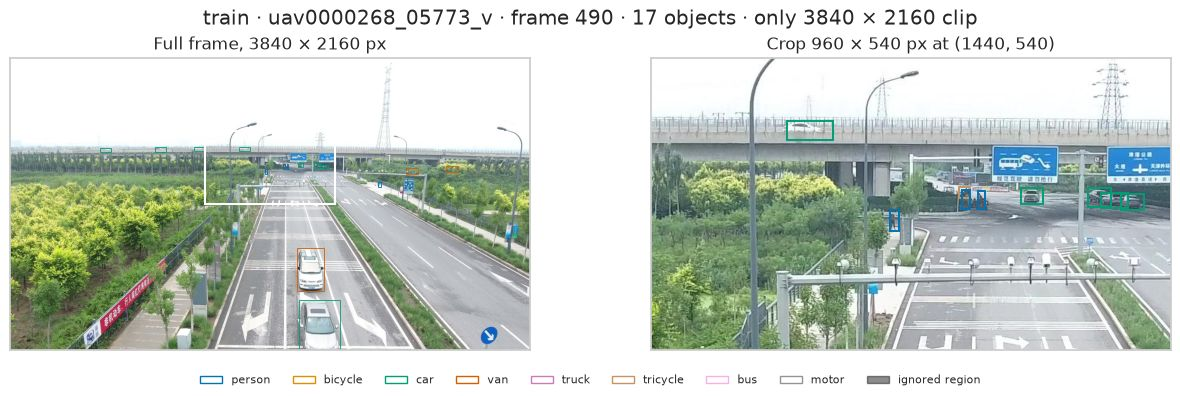

In [40]:
FOCUS_CLASS_IDS = {name: class_id for class_id, name in enumerate(CLASS_NAMES)}
for sample in sample_overview.iter_rows(named=True):
    focus_frames = (
        tracked_objects.filter(
            pl.col("clip") == sample["clip"],
            pl.col("class_id") == FOCUS_CLASS_IDS[sample["focus_class"]],
        )
        .select("split", "image_id", "frame_id")
        .unique()
        .sort("frame_id")
    )
    frame = focus_frames.row(focus_frames.height // 2, named=True)
    frame_keys = (pl.col("split") == frame["split"]) & (pl.col("image_id") == frame["image_id"])
    frame_image = images.filter(frame_keys).row(0, named=True)
    frame_objects = objects.filter(frame_keys)
    crop_size = (frame_image["width"] // 4, frame_image["height"] // 4)
    fig = plot_frame_with_crop(
        Path(frame_image["file_path"]),
        frame_objects,
        ignored.filter(frame_keys),
        find_densest_crop(
            frame_objects,
            (frame_image["width"], frame_image["height"]),
            crop_size,
            max_area=frame_objects.select(pl.col("area").median()).item(),
        ),
        crop_size,
        f"{sample['split']} · {sample['clip']} · frame {frame['frame_id']} · "
        f"{frame_objects.height} objects · {sample['reason']}",
    )
    display(Image(data=render_figure_as_jpeg(fig, quality=80), format="jpeg"))

- Shown frames contain 8 to 150 labelled objects and 0 to 8 ignored regions.
- Focus class instances per shown frame: 49 person (`uav0000086_00000_v`), 63 person (`uav0000138_00000_v`), 4 truck (`uav0000263_03289_v`), 1 bus (`uav0000305_00000_v`), 9 car (`uav0000268_05773_v`).
- Crop sizes range from 336 × 189 px (1344 × 756 frame) to 960 × 540 px (3840 × 2160 frame).

## 11. Validation coverage

Comparison of `val` with `train` (and with `test` where only frame metadata exists) on classes, size buckets, density, frame sizes, ignored regions, and tracks. A condition is flagged when it occurs in `train` but in `val` has fewer than 1,000 instances, appears in at most one clip, or has less than half its `train` share. The split is not changed here.

### 11.1 Classes, sizes, density, and ignored regions

In [41]:
def compare_splits(table: pl.DataFrame, key: str, value: str) -> pl.DataFrame:
    return table.pivot(on="split", index=key, values=value).select(
        pl.col(key).cast(pl.String).alias("condition"),
        pl.col("train").cast(pl.Float64).alias("train"),
        pl.col("val").cast(pl.Float64).alias("val"),
    )


class_tracks = (
    tracks.join(build_class_table(), on="class_id")
    .group_by("split", "class_name")
    .agg(pl.len().alias("tracks"))
    .sort(pl.col("class_name").cast(CLASS_ORDER))
)
coverage_rows = pl.concat(
    [
        compare_splits(class_presence, "class_name", "instance_share")
        .with_columns(pl.lit("instance share").alias("measure")),
        compare_splits(class_presence, "class_name", "instances")
        .with_columns(pl.lit("instances").alias("measure")),
        compare_splits(class_presence, "class_name", "clips")
        .with_columns(pl.lit("clips containing").alias("measure")),
        compare_splits(class_tracks, "class_name", "tracks")
        .with_columns(pl.lit("tracks").alias("measure")),
        compare_splits(
            size_bucket_shares.filter(pl.col("class_name") == "all")
            .unpivot(index="split", on=["small", "medium", "large"], variable_name="bucket"),
            "bucket",
            "value",
        ).with_columns(pl.lit("size bucket share").alias("measure")),
        compare_splits(
            occlusion_shares.filter(pl.col("class_name") == "all")
            .unpivot(index="split", on=OCCLUSION_LEVELS, variable_name="level"),
            "level",
            "value",
        ).with_columns(pl.lit("occlusion share").alias("measure")),
        compare_splits(
            frame_count_summary.unpivot(index="split", on=["p50", "p95", "max"],
                                        variable_name="statistic"),
            "statistic",
            "value",
        ).with_columns(pl.lit("objects per frame").alias("measure")),
        compare_splits(
            summarize_ignored_frames(["split"]).unpivot(
                index="split", on=["share_with_regions", "regions_mean", "covered_mean"],
                variable_name="statistic",
            ),
            "statistic",
            "value",
        ).with_columns(pl.lit("ignored regions").alias("measure")),
    ]
).select("measure", "condition", "train", "val")
coverage = coverage_rows.join(
    coverage_rows.filter(pl.col("measure").is_in(["instances", "clips containing"]))
    .pivot(on="measure", index="condition", values="val")
    .rename({"instances": "val_instances", "clips containing": "val_clips"}),
    on="condition",
    how="left",
).with_columns(
    (pl.col("val") / pl.col("train")).round(2).alias("val_to_train"),
    (
        pl.col("measure").is_in(["instance share", "size bucket share"])
        & (
            (pl.col("val") < 0.5 * pl.col("train"))
            | (pl.col("val_instances") < 1000).fill_null(False)
            | (pl.col("val_clips") <= 1).fill_null(False)
        )
    ).alias("is_flagged"),
).drop("val_instances", "val_clips").with_columns(pl.col("train", "val").round(3))
with pl.Config(tbl_rows=-1):
    display(coverage)

measure,condition,train,val,val_to_train,is_flagged
str,str,f64,f64,f64,bool
"""instance share""","""person""",0.297,0.459,1.55,false
"""instance share""","""bicycle""",0.036,0.059,1.63,false
"""instance share""","""car""",0.46,0.234,0.51,false
"""instance share""","""van""",0.044,0.049,1.12,false
"""instance share""","""truck""",0.026,0.026,0.98,false
"""instance share""","""tricycle""",0.038,0.047,1.26,false
"""instance share""","""bus""",0.008,0.01,1.22,false
"""instance share""","""motor""",0.092,0.116,1.26,false
"""instances""","""person""",330685.0,48328.0,0.15,false


- No condition is flagged. The lowest `val` / `train` ratio of instance share is car (0.51: 23.4% vs 46.0%).
- `val` / `train` ratios: person share 1.55, bicycle share 1.63, truck share 0.98, bus share 1.22, small share 0.79, unoccluded share 0.78, frames with ignored regions 1.05, regions per frame 0.74.
- `val` has 1,021 bus instances in 2 clips and 2,689 truck instances in 5 clips.
- Objects per frame: median 38 in `val` vs 43 in `train`; maximum 116 vs 180.

### 11.2 Frame sizes compared with `test`

All `test` frames are at most 1920 px wide. Frames wider than 1920 px (2688 × 1512, 2720 × 1530, 3840 × 2160) occur only in `train` and `val`.

In [42]:
TEST_MAX_WIDTH = test_images["width"].max()
SPLIT_ORDER = pl.Enum(["train", "val", "test"])
frame_groups = all_images.with_columns(
    pl.col("split").cast(pl.String),
    pl.when(pl.col("width") > TEST_MAX_WIDTH)
    .then(pl.lit("wider than test"))
    .otherwise(pl.lit("within test range"))
    .alias("size_group"),
)
object_groups = (
    object_shapes.join(images.select("split", "image_id", "clip"), on=["split", "image_id"])
    .join(frame_groups.select("split", "clip", "size_group").unique(), on=["split", "clip"])
).with_columns(
    (pl.col("sqrt_area") * compute_resize_scale(MIN_SIZE, MAX_SIZE)).alias("resized_sqrt_area")
)
size_group_shares = (
    frame_groups.group_by("split", "size_group")
    .agg(pl.col("clip").n_unique().alias("clips"), pl.len().alias("frames"))
    .join(
        object_groups.group_by("split", "size_group").len("objects"),
        on=["split", "size_group"],
        how="left",
    )
    .with_columns(
        (pl.col("frames") / pl.col("frames").sum().over("split")).round(3).alias("frame_share"),
        (pl.col("objects") / pl.col("objects").sum().over("split")).round(3)
        .alias("object_share"),
    )
    .sort(pl.col("split").cast(SPLIT_ORDER), "size_group")
)
size_group_shares

split,size_group,clips,frames,objects,frame_share,object_share
str,str,u32,u32,u32,f64,f64
"""train""","""wider than test""",14,4956,277033,0.203,0.249
"""train""","""within test range""",42,19498,837375,0.797,0.751
"""val""","""wider than test""",2,582,41367,0.224,0.393
"""val""","""within test range""",5,2011,63873,0.776,0.607
"""test""","""within test range""",48,3811,null,1.0,null


- Frames wider than any `test` frame (> 1920 px): 582 of 2,593 `val` frames (22.4%) from 2 of 7 clips, holding 41,367 of 105,240 `val` objects (39.3%).
- In `train`: 4,956 of 24,454 frames (20.3%) from 14 of 56 clips, holding 24.9% of objects.
- All 3,811 `test` frames are at most 1920 px wide.

In [43]:
val_groups = object_groups.filter(pl.col("split") == "val").with_columns(
    pl.col("class_name").cast(pl.String)
)


def summarize_size_dependence(groups: pl.DataFrame, label: pl.Expr) -> pl.DataFrame:
    is_wider = pl.col("size_group") == "wider than test"
    return groups.group_by(label.alias("class_or_size_bucket"), maintain_order=True).agg(
        pl.len().alias("objects"),
        is_wider.mean().round(3).alias("share_from_wider_frames"),
        pl.col("resized_sqrt_area").filter(~is_wider).median().round(1)
        .alias("resized_sqrt_area_p50_within"),
        pl.col("resized_sqrt_area").filter(is_wider).median().round(1)
        .alias("resized_sqrt_area_p50_wider"),
    )


val_size_dependence = pl.concat(
    [
        summarize_size_dependence(val_groups, pl.lit("all")),
        summarize_size_dependence(val_groups, pl.col("class_name")).sort(
            pl.col("class_or_size_bucket").cast(CLASS_ORDER)
        ),
        summarize_size_dependence(
            explode_size_buckets(val_groups, pl.col("area")), pl.col("size_bucket").cast(pl.String)
        ).sort(
            pl.col("class_or_size_bucket").cast(pl.Enum(["small", "medium", "large"]))
        ),
    ]
)
with pl.Config(tbl_rows=-1, tbl_cols=-1):
    display(val_size_dependence)

class_or_size_bucket,objects,share_from_wider_frames,resized_sqrt_area_p50_within,resized_sqrt_area_p50_wider
str,u32,f64,f64,f64
"""all""",105240,0.393,50.3,46.8
"""person""",48328,0.393,48.1,42.1
"""bicycle""",6163,0.78,68.8,45.5
"""car""",24652,0.434,65.0,56.3
"""van""",5159,0.273,54.2,61.8
"""truck""",2689,0.17,59.2,116.2
"""tricycle""",4977,0.257,54.0,65.3
"""bus""",1021,0.0,153.9,null
"""motor""",12251,0.306,37.4,42.1


- Share of `val` objects from frames wider than `test`: bicycle 78.0%, car 43.4%, person 39.3%, motor 30.6%, van 27.3%, tricycle 25.7%, truck 17.0%, bus 0%.
- By original-pixel COCO bucket: small 7.0%, medium 43.5%, large 68.2%.
- Median √area after resize: 50.3 px for objects from frames within the `test` range, 46.8 px from wider frames; for small objects 33.0 px and 15.7 px.

### 11.3 Tracks

In [44]:
tracks.join(build_class_table(), on="class_id").group_by("split").agg(
    pl.len().alias("tracks"),
    (pl.col("class_count") > 1).sum().alias("tracks_with_class_change"),
    (pl.col("class_name") == "bus").sum().alias("bus_tracks"),
    (pl.col("class_name") == "truck").sum().alias("truck_tracks"),
).sort("split")

split,tracks,tracks_with_class_change,bus_tracks,truck_tracks
str,u32,u32,u32,u32
"""train""",7354,153,47,141
"""val""",746,8,6,15


- `val` has 6 bus tracks in 2 clips and 15 truck tracks; `train` has 47 and 141.
- Tracks whose class changes between frames: 153 of 7,354 in `train`, 8 of 746 in `val`.

### 11.4 Provided split versus adopted split

`val` composition under the provided split (frames grouped by their source file) and under the adopted split from `config/data.toml`.

In [45]:
def summarize_val_split(val_frames: pl.DataFrame, definition: str) -> pl.DataFrame:
    val_objects = objects.join(val_frames.select("split", "image_id"), on=["split", "image_id"])
    val_clips = val_frames.select("split", "image_id", "clip")
    return pl.DataFrame(
        {
            "split_definition": [definition],
            "val_clips": [val_frames["clip"].n_unique()],
            "val_frames": [val_frames.height],
            "val_objects": [val_objects.height],
            "frames_wider_than_test": [val_frames.filter(pl.col("width") > TEST_MAX_WIDTH).height],
            "bus_instances": [val_objects.filter(pl.col("class_id") == 6).height],
            "bus_clips": [
                val_objects.filter(pl.col("class_id") == 6)
                .join(val_clips, on=["split", "image_id"])["clip"]
                .n_unique()
            ],
            "truck_instances": [val_objects.filter(pl.col("class_id") == 4).height],
            "person_share": [round(val_objects.filter(pl.col("class_id") == 0).height
                                   / val_objects.height, 3)],
        }
    ).with_columns(
        (pl.col("frames_wider_than_test") / pl.col("val_frames")).round(3)
        .alias("wider_frame_share")
    )


pl.concat(
    [
        summarize_val_split(images.filter(pl.col("source_split") == "val"), "provided"),
        summarize_val_split(images.filter(pl.col("split") == "val"), "adopted"),
    ]
)

split_definition,val_clips,val_frames,val_objects,frames_wider_than_test,bus_instances,bus_clips,truck_instances,person_share,wider_frame_share
str,i64,i64,i64,i64,i64,i64,i64,f64,f64
"""provided""",7,2846,114132,1560,264,1,1359,0.441,0.548
"""adopted""",7,2593,105240,582,1021,2,2689,0.459,0.224


- Provided split: 2,846 `val` frames, 114,132 objects, 54.8% of frames wider than `test`, 264 bus instances in 1 clip, 1,359 truck instances, person share 44.1%.
- Adopted split: 2,593 `val` frames, 105,240 objects, 22.4% of frames wider than `test`, 1,021 bus instances in 2 clips, 2,689 truck instances, person share 45.9%.

## 12. Test set

`test` has frames and sizes (`test_images.csv`) but no labels. It is described here and not used to choose anything. Frame sizes are compared in section 3 and resize scales in section 5.4. This section compares clip length, frame spacing, and image appearance with `train` and `val`, using thumbnails that keep every 8th pixel. `test` is drawn dashed in figures.

### 12.1 Clip length and frame numbering

In [46]:
ALL_SPLIT_COLORS = {**SPLIT_COLORS, "test": TEST_COLOR}
SPLIT_LINESTYLES = {"train": "-", "val": "-", "test": "--"}
all_frames = pl.concat(
    [
        images.select("split", "clip", "frame_id", "file_path"),
        test_images.select("split", "clip", "frame_id", "file_path"),
    ]
)
frame_numbering = all_frames.sort("split", "clip", "frame_id").with_columns(
    pl.col("frame_id").diff().over("split", "clip").alias("step")
).group_by("split").agg(
    pl.col("clip").n_unique().alias("clips"),
    pl.len().alias("frames"),
    pl.col("frame_id").min().alias("first_frame_id"),
    (pl.col("step") == 1).sum().alias("steps_of_1"),
    (pl.col("step") > 1).sum().alias("steps_above_1"),
).join(
    all_frames.group_by("split", "clip").len("clip_frames").group_by("split").agg(
        pl.col("clip_frames").min().alias("frames_per_clip_min"),
        pl.col("clip_frames").median().alias("frames_per_clip_median"),
        pl.col("clip_frames").max().alias("frames_per_clip_max"),
    ),
    on="split",
).sort(pl.col("split").cast(pl.Enum(list(ALL_SPLIT_COLORS))))
with pl.Config(tbl_cols=-1):
    display(frame_numbering)

split,clips,frames,first_frame_id,steps_of_1,steps_above_1,frames_per_clip_min,frames_per_clip_median,frames_per_clip_max
str,u32,u32,i64,u32,u32,u32,f64,u32
"""train""",56,24454,1,24398,0,58,383.5,1424
"""val""",7,2593,1,2586,0,184,349.0,725
"""test""",48,3811,1,3763,0,35,73.5,148


- `test`: 48 clips, 3,811 frames, 35 to 148 frames per clip (median 73.5); `train` 58 to 1,424 (median 383.5); `val` 184 to 725 (median 349).
- In all three splits, frame numbers start at 1 and every step between consecutive frames of a clip is 1.

### 12.2 Change between consecutive frames

Mean absolute luminance difference between thumbnails of frames $t$ and $t + k$, for 4 evenly spaced start frames per clip.

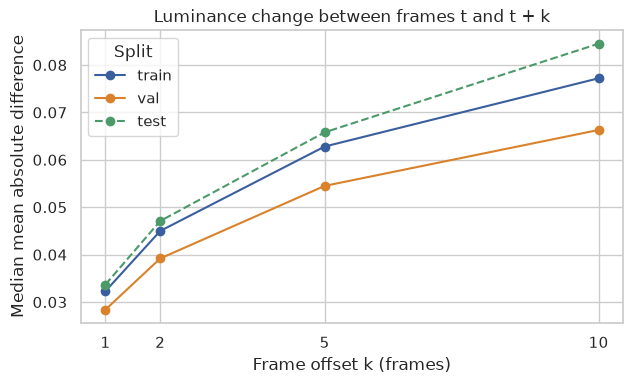

split,offset,pairs,difference_p50,difference_p90
str,i64,u32,f64,f64
"""train""",1,224,0.0323,0.0735
"""train""",2,224,0.045,0.0916
"""train""",5,224,0.0628,0.1183
"""train""",10,224,0.0772,0.1367
"""val""",1,28,0.0284,0.0728
"""val""",2,28,0.0392,0.0892
"""val""",5,28,0.0545,0.1114
"""val""",10,28,0.0663,0.1286
"""test""",1,192,0.0337,0.0667


In [47]:
FRAME_OFFSETS = (1, 2, 5, 10)
THUMBNAIL_STRIDE = 8
frame_differences = compute_frame_differences(
    sample_frame_pairs(all_frames, FRAME_OFFSETS, starts_per_clip=4), THUMBNAIL_STRIDE
)
difference_summary = (
    frame_differences.group_by("split", "offset")
    .agg(
        pl.len().alias("pairs"),
        pl.col("mean_abs_difference").median().round(4).alias("difference_p50"),
        pl.col("mean_abs_difference").quantile(0.9, "linear").round(4).alias("difference_p90"),
    )
    .sort(pl.col("split").cast(pl.Enum(list(ALL_SPLIT_COLORS))), "offset")
)
fig, ax = plt.subplots(figsize=(7, 3.8))
for split, color in ALL_SPLIT_COLORS.items():
    rows = difference_summary.filter(pl.col("split") == split)
    ax.plot(rows["offset"], rows["difference_p50"], color=color, marker="o",
            linestyle=SPLIT_LINESTYLES[split], label=split)
ax.set(xlabel="Frame offset k (frames)", ylabel="Median mean absolute difference",
       xticks=FRAME_OFFSETS, title="Luminance change between frames t and t + k")
ax.legend(title="Split")
plt.show()
with pl.Config(tbl_rows=-1):
    display(difference_summary)

| k (frames) | 1 | 2 | 5 | 10 |
| --- | --- | --- | --- | --- |
| `train` | 0.0323 | 0.0450 | 0.0628 | 0.0772 |
| `val` | 0.0284 | 0.0392 | 0.0545 | 0.0663 |
| `test` | 0.0337 | 0.0471 | 0.0658 | 0.0845 |

- Median mean absolute luminance difference; `test` is within 0.0030 of `train` for k ≤ 5 and 0.0073 above it at k = 10.

### 12.3 Image appearance

Mean luminance and luminance standard deviation (contrast) per frame, on every 25th frame of `train` and `val` and every 5th frame of `test`.

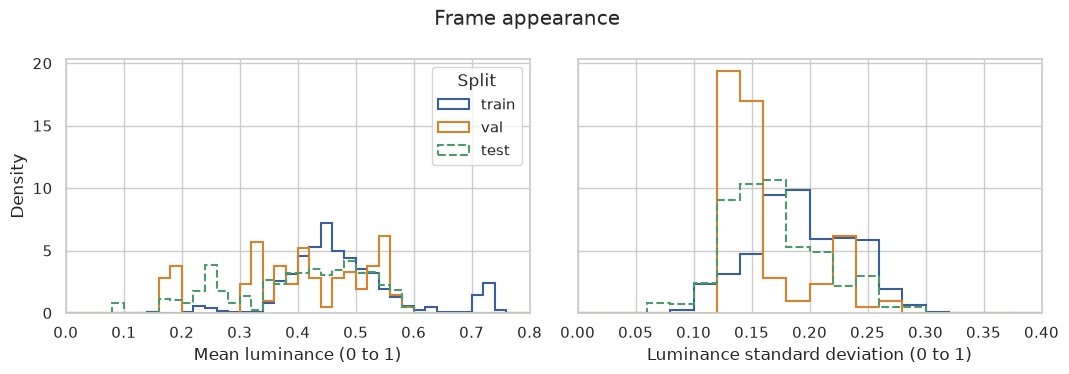

split,frames,mean_r,mean_g,mean_b,luminance_p50,contrast_p50,share_luminance_below_0.25,mean_rgb_255
str,u32,f64,f64,f64,f64,f64,f64,list[i64]
"""train""",1004,0.464,0.486,0.472,0.46,0.186,0.021,"[118, 124, 120]"
"""val""",106,0.41,0.407,0.407,0.414,0.145,0.132,"[105, 104, 104]"
"""test""",780,0.408,0.396,0.395,0.421,0.165,0.15,"[104, 101, 101]"


In [48]:
appearance_frames = all_frames.filter(
    ((pl.col("frame_id") - 1) % pl.when(pl.col("split") == "test").then(5).otherwise(25)) == 0
)
appearance = compute_color_statistics(
    appearance_frames["file_path"].to_list(), THUMBNAIL_STRIDE
).join(appearance_frames.select("split", "file_path"), on="file_path")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (column, label) in zip(
    axes, [("luminance_mean", "Mean luminance"), ("luminance_std", "Luminance standard deviation")]
):
    for split, color in ALL_SPLIT_COLORS.items():
        values = appearance.filter(pl.col("split") == split)[column].to_numpy()
        ax.hist(values, bins=list(np.linspace(0, 1, 51)), density=True, histtype="step",
                linewidth=1.5, color=color, linestyle=SPLIT_LINESTYLES[split], label=split)
    ax.set(xlabel=f"{label} (0 to 1)", xlim=(0, 0.8 if column == "luminance_mean" else 0.4))
axes[0].set_ylabel("Density")
axes[0].legend(title="Split")
fig.suptitle("Frame appearance")
fig.tight_layout()
plt.show()
appearance_summary = appearance.group_by("split").agg(
    pl.len().alias("frames"),
    *(pl.col(c).mean().round(3) for c in ("mean_r", "mean_g", "mean_b")),
    pl.col("luminance_mean").median().round(3).alias("luminance_p50"),
    pl.col("luminance_std").median().round(3).alias("contrast_p50"),
    (pl.col("luminance_mean") < 0.25).mean().round(3).alias("share_luminance_below_0.25"),
).with_columns(
    pl.concat_list(
        (pl.col(c) * 255).round(0).cast(pl.Int64) for c in ("mean_r", "mean_g", "mean_b")
    ).alias("mean_rgb_255")
).sort(pl.col("split").cast(pl.Enum(list(ALL_SPLIT_COLORS))))
with pl.Config(tbl_cols=-1):
    display(appearance_summary)

- Median frame luminance: 0.460 in `train`, 0.414 in `val`, 0.421 in `test`; median contrast 0.186, 0.145, 0.165.
- Frames with mean luminance below 0.25: 2.1% of sampled `train` frames (1,004), 13.2% of `val` (106), 15.0% of `test` (780).

### 12.4 Test frames

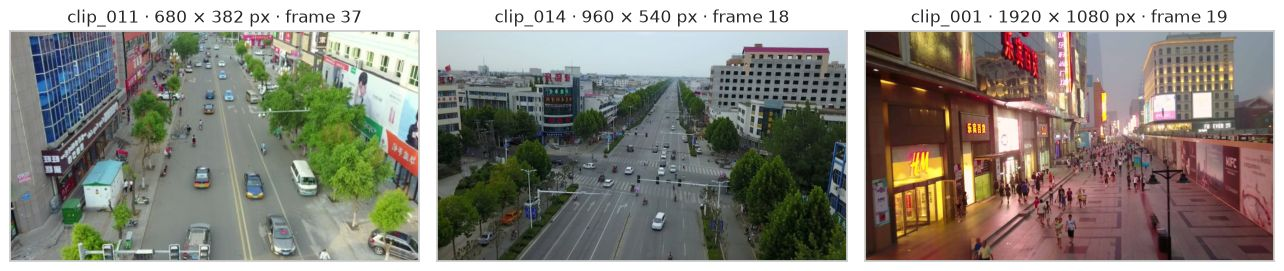

In [49]:
test_examples = (
    test_images.sort("width", "clip")
    .group_by("width", maintain_order=True)
    .first()
    .filter(pl.col("width").is_in([680, 960, 1920]))
)
fig, axes = plt.subplots(1, 3, figsize=(13, 2.7))
for ax, example in zip(axes, test_examples.iter_rows(named=True)):
    middle_frame = test_images.filter(pl.col("clip") == example["clip"]).sort("frame_id")
    middle_frame = middle_frame.row(middle_frame.height // 2, named=True)
    ax.imshow(plt.imread(middle_frame["file_path"]))
    ax.set(xticks=[], yticks=[], title=f"{example['clip']} · {example['width']} × "
           f"{example['height']} px · frame {middle_frame['frame_id']}")
    ax.grid(False)
fig.tight_layout()
display(Image(data=render_figure_as_jpeg(fig, quality=80), format="jpeg"))

- Middle frames of `clip_011` (680 × 382 px), `clip_014` (960 × 540 px), and `clip_001` (1920 × 1080 px).

## 13. Anchor shapes

`train` boxes of the adopted split, resized like the baselines (`min_size` 1024, `max_size` 1824). Box shapes are clustered with k-means using $1 - \text{IoU}$ as the distance, as in [YOLOv2](https://arxiv.org/abs/1612.08242) (`src.models.anchors`, seed 42), and compared with the default anchors of torchvision Faster R-CNN ResNet50-FPN v2 and RetinaNet ResNet50-FPN v2, read from the installed torchvision.

Two IoU variants: *shape* IoU places box and anchor at a common center (the k-means measure); *grid* IoU places anchors at their feature-map centers $(i \cdot s, j \cdot s)$ for stride $s$ and takes the best of the four grid points around the box center, which is what the anchor matcher sees. COCO size buckets use the original box area.

### 13.1 k-means on box shapes

In [50]:
BASELINE_MIN_SIZE, BASELINE_MAX_SIZE = 1024, 1824
KMEANS_SIZES = (5, 9, 15)
train_boxes = (
    object_shapes.filter(pl.col("split") == "train")
    .with_columns(compute_resize_scale(BASELINE_MIN_SIZE, BASELINE_MAX_SIZE).alias("scale"))
    .with_columns(pl.col("x", "y", "w", "h") * pl.col("scale"))
)
train_box_array = train_boxes.select("x", "y", "w", "h").to_numpy()
kmeans_results = {
    k: cluster_box_shapes(train_box_array[:, 2:], k, seed=SEED, max_iterations=300)
    for k in KMEANS_SIZES
}
pl.DataFrame(
    {
        "k": list(KMEANS_SIZES),
        "mean_iou_with_nearest_centroid": [round(kmeans_results[k][1], 4) for k in KMEANS_SIZES],
    }
)

k,mean_iou_with_nearest_centroid
i64,f64
5,0.6369
9,0.7048
15,0.7608


In [51]:
kmeans_centroids = pl.concat(
    pl.DataFrame(kmeans_results[k][0], schema=["w", "h"], orient="row").with_columns(
        pl.lit(k).alias("k"),
        pl.int_range(1, pl.len() + 1).alias("rank_by_area"),
        (pl.col("w") * pl.col("h")).sqrt().alias("sqrt_area"),
        (pl.col("h") / pl.col("w")).alias("aspect_ratio"),
    )
    for k in KMEANS_SIZES
).select("k", "rank_by_area", "w", "h", "sqrt_area", "aspect_ratio").with_columns(
    pl.selectors.float().round(2)
)
with pl.Config(tbl_rows=-1, fmt_str_lengths=200):
    display(kmeans_centroids)

k,rank_by_area,w,h,sqrt_area,aspect_ratio
i32,i64,f64,f64,f64,f64
5,1,23.98,32.15,27.76,1.34
5,2,63.57,38.49,49.47,0.61
5,3,41.99,66.14,52.7,1.58
5,4,109.38,84.15,95.94,0.77
5,5,201.7,150.52,174.24,0.75
9,1,19.5,27.07,22.97,1.39
9,2,28.38,50.41,37.82,1.78
9,3,46.66,32.06,38.68,0.69
9,4,48.43,71.43,58.82,1.47


- Mean IoU of `train` boxes with their nearest centroid: 0.637 (k = 5), 0.705 (k = 9), 0.761 (k = 15).
- k = 9 centroids: √area 23.0 to 226.3 px, h / w 0.50 to 1.78; k = 15 centroids: √area 19.2 to 242.0 px, h / w 0.49 to 2.11.

### 13.2 Default torchvision anchors

In [52]:
default_anchors = {
    name: load_default_anchors(architecture)
    for name, architecture in [
        ("faster_rcnn", "fasterrcnn_resnet50_fpn_v2"),
        ("retinanet", "retinanet_resnet50_fpn_v2"),
    ]
}
anchor_listing = pl.concat(
    anchors.with_columns(pl.lit(name).alias("model")) for name, anchors in default_anchors.items()
).group_by("model", "level", "stride", maintain_order=True).agg(
    pl.len().alias("anchors"),
    pl.format("{}×{}", pl.col("w").cast(pl.Int64), pl.col("h").cast(pl.Int64))
    .str.join(", ")
    .alias("w_x_h"),
)
with pl.Config(tbl_rows=-1, fmt_str_lengths=200):
    display(anchor_listing)

model,level,stride,anchors,w_x_h
str,i64,i64,u32,str
"""faster_rcnn""",0,4,3,"""46×22, 32×32, 22×46"""
"""faster_rcnn""",1,8,3,"""90×46, 64×64, 46×90"""
"""faster_rcnn""",2,16,3,"""182×90, 128×128, 90×182"""
"""faster_rcnn""",3,32,3,"""362×182, 256×256, 182×362"""
"""faster_rcnn""",4,64,3,"""724×362, 512×512, 362×724"""
"""retinanet""",0,8,9,"""46×22, 56×28, 70×36, 32×32, 40×40, 50×50, 22×46, 28×56, 36×70"""
"""retinanet""",1,16,9,"""90×46, 114×56, 142×72, 64×64, 80×80, 100×100, 46×90, 56×114, 72×142"""
"""retinanet""",2,32,9,"""182×90, 228×114, 288×144, 128×128, 160×160, 204×204, 90×182, 114×228, 144×288"""
"""retinanet""",3,64,9,"""362×182, 456×228, 574×288, 256×256, 322×322, 406×406, 182×362, 228×456, 288×574"""


- Faster R-CNN: 15 anchors, 3 per level (sizes 32 to 512 px, h / w 0.5, 1, 2) on strides 4 to 64 px.
- RetinaNet: 45 anchors, 9 per level (sizes 32 to 812 px, three per octave, h / w 0.5, 1, 2) on strides 8 to 128 px.
- The smallest anchors of both models are 32 × 32, 46 × 22, and 22 × 46 px; in RetinaNet they sit on stride 8, in Faster R-CNN on stride 4.

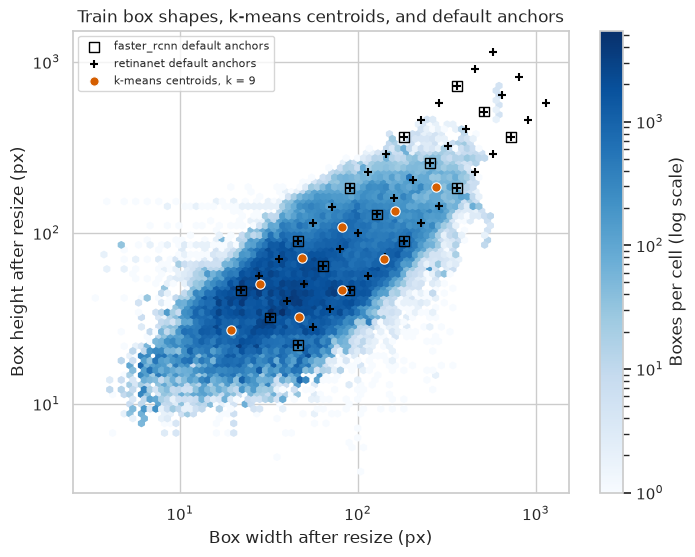

In [53]:
fig, ax = plt.subplots(figsize=(8, 6))
hexbins = ax.hexbin(
    train_box_array[:, 2], train_box_array[:, 3], gridsize=70, xscale="log", yscale="log",
    bins="log", cmap="Blues", mincnt=1,
)
fig.colorbar(hexbins, ax=ax, label="Boxes per cell (log scale)")
ax.scatter(default_anchors["faster_rcnn"]["w"], default_anchors["faster_rcnn"]["h"], marker="s",
           s=50, facecolors="none", edgecolors="black", label="faster_rcnn default anchors")
ax.scatter(default_anchors["retinanet"]["w"], default_anchors["retinanet"]["h"], marker="+",
           s=40, color="black", label="retinanet default anchors")
centroids = kmeans_results[9][0]
ax.scatter(centroids[:, 0], centroids[:, 1], marker="o", s=45, color="#d55e00",
           edgecolors="white", linewidths=0.8, label="k-means centroids, k = 9")
ax.set(xlabel="Box width after resize (px)", ylabel="Box height after resize (px)",
       title="Train box shapes, k-means centroids, and default anchors")
ax.legend(loc="upper left", fontsize=8)
plt.show()

- The k = 9 centroid with the smallest area is 19.5 × 27.1 px, below the smallest default anchor area of 32 × 32 px.
- The largest k = 9 centroid is 275.9 × 185.5 px; default anchors extend to 724 × 362 px (Faster R-CNN) and 1148 × 574 px (RetinaNet).

### 13.3 Boxes without a well-matching default anchor

Share of `train` boxes whose best IoU with any anchor is below 0.7 and 0.3 (Faster R-CNN RPN positive and negative thresholds) and below 0.5 and 0.4 (RetinaNet positive and negative thresholds). The k-means rows use shape IoU with the centroids as anchors and are given for reference.

In [54]:
IOU_THRESHOLDS = (0.7, 0.5, 0.4, 0.3)
best_iou_columns = {
    f"{name}_{'grid' if is_grid else 'shape'}": compute_best_anchor_iou(
        train_box_array, anchors, is_grid_aligned=is_grid
    )
    for name, anchors in default_anchors.items()
    for is_grid in (True, False)
} | {
    f"kmeans_{k}_shape": compute_best_anchor_iou(
        train_box_array, pl.DataFrame(kmeans_results[k][0], schema=["w", "h"], orient="row"),
        is_grid_aligned=False,
    )
    for k in KMEANS_SIZES
}
box_best_iou = train_boxes.select("area").with_columns(
    pl.Series(name, values) for name, values in best_iou_columns.items()
)
# size buckets use the original box area; boundary boxes count in both buckets, as in COCO
anchor_coverage = (
    pl.concat(
        [
            box_best_iou.with_columns(pl.lit("all").alias("size_bucket")),
            explode_size_buckets(box_best_iou, pl.col("area"))
            .with_columns(pl.col("size_bucket").cast(pl.String)),
        ]
    )
    .drop("area")
    .unpivot(index="size_bucket", variable_name="anchor_set", value_name="best_iou")
    .group_by("anchor_set", "size_bucket", maintain_order=True)
    .agg(
        pl.len().alias("boxes"),
        pl.col("best_iou").mean().alias("mean_best_iou"),
        *((pl.col("best_iou") < t).mean().alias(f"below_{t}") for t in IOU_THRESHOLDS),
    )
    .with_columns(pl.selectors.float().round(3))
    .sort(
        pl.col("anchor_set").cast(pl.Enum(list(best_iou_columns))),
        pl.col("size_bucket").cast(pl.Enum(["all", "small", "medium", "large"])),
    )
)
with pl.Config(tbl_rows=-1, tbl_cols=-1):
    display(anchor_coverage)

anchor_set,size_bucket,boxes,mean_best_iou,below_0.7,below_0.5,below_0.4,below_0.3
str,str,u32,f64,f64,f64,f64,f64
"""faster_rcnn_grid""","""all""",1114408,0.652,0.568,0.105,0.064,0.034
"""faster_rcnn_grid""","""small""",277030,0.557,0.709,0.37,0.243,0.132
"""faster_rcnn_grid""","""medium""",709033,0.683,0.524,0.019,0.006,0.002
"""faster_rcnn_grid""","""large""",128719,0.692,0.502,0.003,0.0,0.0
"""faster_rcnn_shape""","""all""",1114408,0.664,0.538,0.103,0.064,0.034
"""faster_rcnn_shape""","""small""",277030,0.565,0.678,0.37,0.243,0.132
"""faster_rcnn_shape""","""medium""",709033,0.696,0.495,0.018,0.006,0.002
"""faster_rcnn_shape""","""large""",128719,0.706,0.474,0.002,0.0,0.0
"""retinanet_grid""","""all""",1114408,0.706,0.297,0.103,0.065,0.034


| grid IoU, `train` boxes | Faster R-CNN | RetinaNet |
| --- | --- | --- |
| best IoU < 0.7, all | 56.8% | 29.7% |
| best IoU < 0.5, all | 10.5% | 10.3% |
| best IoU < 0.4, all | 6.4% | 6.5% |
| best IoU < 0.5, small | 37.0% | 37.5% |
| best IoU < 0.4, small | 24.3% | 24.5% |
| best IoU < 0.5, medium | 1.9% | 1.6% |
| best IoU < 0.5, large | 0.3% | 0.2% |

- Shape IoU gives shares below 0.5 within 0.2 percentage points of grid IoU for both default sets.
- k-means centroids as anchors (shape IoU): best IoU < 0.5 for 5.1% of boxes with k = 9 and 2.3% with k = 15; for small boxes 14.3% and 6.8%.

## 14. Summary

Key measured numbers from sections 2 to 13, taken from the tables above. `train` and `val` use the adopted split; `test` has no labels, so only frame statistics are given.

In [55]:
def pick(table: pl.DataFrame, column: str, **filters: str | int) -> float:
    rows = table.filter(
        *(pl.col(name).cast(pl.String) == str(value) for name, value in filters.items())
    )
    return rows[column].item()


def percent(value: float) -> str:
    return f"{100 * value:.1f}%"


def size_range(split: str) -> str:
    sizes = frame_sizes.filter(pl.col("split") == split).sort("width")
    return f"{sizes['width'][0]}×{sizes['height'][0]} to {sizes['width'][-1]}×{sizes['height'][-1]}"


LABELLED = ("train", "val")
summary_rows = [
    ("2", "clips", *(str(pick(frame_numbering, "clips", split=s)) for s in SPLITS)),
    ("2", "frames", *(str(pick(frame_numbering, "frames", split=s)) for s in SPLITS)),
    ("2", "labelled objects", *(str(pick(split_overview, "objects", split=s)) for s in LABELLED),
     ""),
    ("2", "unique ignored regions",
     *(str(pick(split_overview, "ignored_regions", split=s)) for s in LABELLED), ""),
    ("3", "frame sizes (px)", *(size_range(s) for s in SPLITS)),
    ("11.2", "frames wider than 1920 px",
     *(percent(pick(size_group_shares, "frame_share", split=s, size_group="wider than test"))
       for s in LABELLED), "0.0%"),
    ("4", "person instance share",
     *(percent(pick(class_presence, "instance_share", split=s, class_name="person"))
       for s in LABELLED), ""),
    ("4", "car instance share",
     *(percent(pick(class_presence, "instance_share", split=s, class_name="car"))
       for s in LABELLED), ""),
    ("4", "bus instances (clips)",
     *(f"{pick(class_presence, 'instances', split=s, class_name='bus')} "
       f"({pick(class_presence, 'clips', split=s, class_name='bus')})" for s in LABELLED), ""),
    ("5.1", "median √area, original (px)",
     *(f"{pick(box_sizes, 'sqrt_area_p50', split=s, class_name='all'):.1f}" for s in LABELLED),
     ""),
    ("5.5", "median √area after resize (px)",
     *(f"{pick(resized_sizes, 'resized_sqrt_area_p50', split=s, class_name='all'):.1f}"
       for s in LABELLED), ""),
    ("5.2", "small / medium / large share",
     *(" / ".join(percent(pick(size_bucket_shares, b, split=s, class_name="all"))
                  for b in ("small", "medium", "large")) for s in LABELLED), ""),
    ("5.5", "objects below 16 px after resize",
     *(percent(pick(resized_sizes, "resized_sqrt_area_below_16", split=s, class_name="all"))
       for s in LABELLED), ""),
    ("5.4", "required max_size at min_size 1024 (px)",
     *(str(frame_resize.filter(pl.col("split") == s)["required_max_size"].max())
       for s in SPLITS)),
    ("6.1", "objects per frame, median / p95 / max",
     *(" / ".join(f"{pick(frame_count_summary, c, split=s):.0f}" for c in ("p50", "p95", "max"))
       for s in LABELLED), ""),
    ("6.3", "objects with same-class IoU > 0.5",
     *(percent(pick(overlap_shares, "same_class_iou_above_0.5", split=s, class_name="all"))
       for s in LABELLED), ""),
    ("7.1", "frames with ignored regions",
     *(percent(pick(summarize_ignored_frames(["split"]), "share_with_regions", split=s))
       for s in LABELLED), ""),
    ("7.3", "objects more than half inside ignored regions",
     *(percent(pick(coverage_shares, "share_above_0.5", split=s, class_name="all"))
       for s in LABELLED), ""),
    ("8.1", "heavily occluded objects",
     *(percent(pick(occlusion_shares, "heavy", split=s, class_name="all")) for s in LABELLED),
     ""),
    ("8.2", "truncated objects",
     *(percent(pick(truncation_shares, "truncated_share", split=s, class_name="all"))
       for s in LABELLED), ""),
    ("9.1", "median IoU of a track, k = 1 / 5",
     *(" / ".join(f"{pick(offset_summary, 'iou_p50', split=s, offset=k):.3f}" for k in (1, 5))
       for s in LABELLED), ""),
    ("9.2", "tracks, median length (frames)",
     *(f"{tracks.filter(pl.col('split') == s).height}, "
       f"{tracks.filter(pl.col('split') == s)['frames'].median():.0f}" for s in LABELLED), ""),
    ("12.1", "frames per clip, median",
     *(f"{pick(frame_numbering, 'frames_per_clip_median', split=s):.1f}" for s in SPLITS)),
    ("12.3", "frames with mean luminance below 0.25",
     *(percent(pick(appearance_summary, "share_luminance_below_0.25", split=s))
       for s in SPLITS)),
    ("13.3", "boxes with best default-anchor IoU < 0.5 (Faster R-CNN / RetinaNet, grid)",
     " / ".join(percent(pick(anchor_coverage, "below_0.5", anchor_set=f"{name}_grid",
                             size_bucket="all")) for name in ("faster_rcnn", "retinanet")),
     "", ""),
    ("13.3", "small boxes with best default-anchor IoU < 0.5 (Faster R-CNN / RetinaNet)",
     " / ".join(percent(pick(anchor_coverage, "below_0.5", anchor_set=f"{name}_grid",
                             size_bucket="small")) for name in ("faster_rcnn", "retinanet")),
     "", ""),
    ("13.1", "k-means mean IoU, k = 5 / 9 / 15",
     " / ".join(f"{kmeans_results[k][1]:.3f}" for k in KMEANS_SIZES), "", ""),
]
eda_summary = pl.DataFrame(
    summary_rows, schema=["section", "measure", "train", "val", "test"], orient="row"
)
with pl.Config(tbl_rows=-1, fmt_str_lengths=80, tbl_width_chars=200):
    display(eda_summary)

section,measure,train,val,test
str,str,str,str,str
"""2""","""clips""","""56""","""7""","""48"""
"""2""","""frames""","""24454""","""2593""","""3811"""
"""2""","""labelled objects""","""1114408""","""105240""",""""""
"""2""","""unique ignored regions""","""62929""","""4909""",""""""
"""3""","""frame sizes (px)""","""1344×756 to 3840×2160""","""1344×756 to 2720×1530""","""680×382 to 1920×1080"""
"""11.2""","""frames wider than 1920 px""","""20.3%""","""22.4%""","""0.0%"""
"""4""","""person instance share""","""29.7%""","""45.9%""",""""""
"""4""","""car instance share""","""46.0%""","""23.4%""",""""""
"""4""","""bus instances (clips)""","""8896 (23)""","""1021 (2)""",""""""


- 27 measures from sections 2 to 13; `test` values are frame statistics only, the anchor rows use `train` boxes only.